In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import  matplotlib.pyplot as plt
import re
import math

In [2]:
df_final= pd.read_excel('C:/Users/pc/Documents/my_thesis/research_data/new data/final_imp.xlsx')

In [3]:
import sys

print("Python version:", sys.version)
print("Python executable:", sys.executable)

Python version: 3.13.5 | packaged by Anaconda, Inc. | (main, Jun 12 2025, 16:37:03) [MSC v.1929 64 bit (AMD64)]
Python executable: C:\Users\pc\anaconda3\python.exe


In [4]:

# Calculate IQR upper bound
Q1 = df_final['LOS_days'].quantile(0.25)
Q3 = df_final['LOS_days'].quantile(0.75)
IQR = Q3 - Q1
upper_bound = Q3 + 1.5* IQR

# Keep only valid LOS_days
df_final = df_final[(df_final['LOS_days'] >= 1) & (df_final['LOS_days'] <= upper_bound)]

In [5]:

clinical_limits = {
    'hr': (30, 250),
    'sbp': (40, 300),
    'dbp': (20, 180),
    'rr': (5, 80),
    'temp': (30, 45),
    'spo2': (0, 101),
    'rbs': (20, 1000),
    'Pain_score': (0, 10),
    'sodium': (100, 180),
    'potassium': (1.5, 10),

    'wbc': (0.1, 300),
    'rbc': (0.5, 10),

    'basophil': (0, 20),
    'eosinophil': (0, 40),
    'monocyte': (0, 30),
    'neutrophil': (0, 100),
    'lymphocyte': (0, 100),
    'hemoglobin': (2, 25),
    'hematocrit': (5, 80),
    'mcv': (50, 150),
    'mch': (10, 50),
    'mchc': (20, 45),
    'mpv': (5, 20),
    'plt': (5, 2000),
    'ast_sgot': (0, 5000),
    'alt_sgpt': (0, 5000),
    'creatinine': (0.1, 20),
    'oxy_use': (0, 100),
    'Age_years': (13, 120)
}
# Backup Original Dataset
df_original = df_final.copy()
# Replace Clinical Outliers with NaN
# ==========================================
print("Replacing values outside clinical limits...\n")

for col, (low, high) in clinical_limits.items():

    outliers = (df_final[col] < low) | (df_final[col] > high)
    n_outliers = outliers.sum()

    df_final.loc[outliers, col] = np.nan

Replacing values outside clinical limits...



In [6]:
df_final['LOS_binary'] = df_final['LOS_days'].apply(
    lambda x: '<=7_days' if x <= 7 else '>7_days'
).astype('category')

In [7]:
df_final['LOS_binary'].value_counts()

LOS_binary
>7_days     2099
<=7_days    1383
Name: count, dtype: int64

In [8]:
# ============================================================
# REVERSE NUMERIC CODES BACK TO ORIGINAL CATEGORY NAMES
# ============================================================

# 1. Admission source
admit_reverse_map = {
    '1': 'Emergency',
    '2': 'Medical Ward',
    '3': 'Surgical Ward',
    '4': 'Pediatrics Ward',
    '5': 'Maternity Ward',
    '6': 'Orthopedic Ward',
    '7': 'HDU',
    '8': 'Other Specialty Wards'
}

df_final['Admission_source'] = (
    df_final['Admission_source']
    .astype(str)
    .replace(admit_reverse_map)
)


# 2. Diagnosis superclass
diag_reverse_map = {
    '1': 'Cardiovascular Disease',
    '2': 'Respiratory Disease',
    '3': 'Neurological Disease',
    '4': 'Sepsis / Infection',
    '5': 'Gastrointestinal / Hepatic Disease',
    '6': 'Trauma / Toxicology',
    '7': 'Endocrine / Metabolic Disease',
    '8': 'Renal Disease',
    '9': 'Thromboembolism',
    '10': 'Malignancy',
    '11': 'Multi-organ Failure',
    '12': 'Obstetric / Gynecology',
    '13': 'Autoimmune / Systemic Disease',
    '14': 'Other'
}

df_final['case_category'] = (
    df_final['case_category']
    .astype(str)
    .replace(diag_reverse_map)
)

In [9]:
# ============================================================
# CONVERT LOS OUTCOME TO BINARY NUMERIC FORMAT
# ============================================================

df_final['LOS_binary'] = df_final['LOS_binary'].map({
    '<=7_days': 0,
    '>7_days': 1
})

print(df_final['LOS_binary'].value_counts())

LOS_binary
1    2099
0    1383
Name: count, dtype: int64


In [11]:
df_final.rename(columns={"oxy_use": "oxygen_consumption"}, inplace=True)
df_final["oxygen_support"] = pd.cut(
    df_final["oxygen_consumption"],
    bins=[-float("inf"), 0, 8, 20, float("inf")],
    labels=[
        "Off oxygen",
        "Intranasal_O2_support",
        "Facemask O2_support",
        "Mechanical ventilation" ],
    right=True,
    include_lowest=True)

In [12]:

# Avoid division by zero
eps = 1e-6
# 3. Shock Index (SI)
df_final['Shock_Index'] = df_final['hr'] / (df_final['sbp'] + eps)
# Create WBC-Temperature interaction feature
df_final['WBC_Temperature_Interaction'] = df_final['wbc'] * df_final['temp']

In [13]:
# KEEP ONLY SELECTED VARIABLES FOR MACHINE LEARNING
selected_columns = [
     'dbp',
    'Shock_Index',
    'spo2',
    'rbs',
    'sodium',
    'potassium',
    'neutrophil',
    'lymphocyte',
    'plt',
    'Admission_source',
    'case_category',
    'Age_years',
    'oxygen_support',
    'creatinine',
    'LOS_binary',
    'rr',
    'ast_sgot',
   'hemoglobin',
   'monocyte',
   'Pain_score',
    'WBC_Temperature_Interaction']
# Keep ONLY the selected columns that exist
df_final = df_final[
    [col for col in selected_columns if col in df_final.columns]
].copy()  

# TRAIN-TEST SPLIT

In [14]:
# ============================================================
# STRATIFIED 70/15/15 TRAIN–VALIDATION–TEST SPLIT
# Outcome variable: LOS_binary
# Classes:
#   0 = <=7_days
#   1 = >7_days
# ============================================================

import pandas as pd
from sklearn.model_selection import train_test_split

# ------------------------------------------------------------
# 1. Reproducibility
# ------------------------------------------------------------

random_state = 42

# ------------------------------------------------------------
# 2. Verify LOS outcome is already coded as 0 and 1
# ------------------------------------------------------------

print("LOS_binary unique values:", sorted(df_final['LOS_binary'].dropna().unique()))

# ------------------------------------------------------------
# 3. Separate predictors and outcome
# ------------------------------------------------------------

X = df_final.drop(columns=['LOS_binary'])
y = df_final['LOS_binary']

# ------------------------------------------------------------
# 4. First split: 70% training, 30% temporary
# ------------------------------------------------------------

X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=random_state,
    stratify=y,
    shuffle=True
)

# ------------------------------------------------------------
# 5. Second split: 15% validation, 15% test
# ------------------------------------------------------------

X_validation, X_test, y_validation, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=random_state,
    stratify=y_temp,
    shuffle=True
)

# ------------------------------------------------------------
# 6. Create final train, validation, and test datasets
# ------------------------------------------------------------

train = X_train.copy()
train['LOS_binary'] = y_train.values

validation = X_validation.copy()
validation['LOS_binary'] = y_validation.values

test = X_test.copy()
test['LOS_binary'] = y_test.values

# Reset indexes
train = train.reset_index(drop=True)
validation = validation.reset_index(drop=True)
test = test.reset_index(drop=True)

X_train = X_train.reset_index(drop=True)
y_train = y_train.reset_index(drop=True)

X_validation = X_validation.reset_index(drop=True)
y_validation = y_validation.reset_index(drop=True)

X_test = X_test.reset_index(drop=True)
y_test = y_test.reset_index(drop=True)

# ------------------------------------------------------------
# 7. Check dataset sizes
# ------------------------------------------------------------

print("\nFinal dataset sizes:")
print(f"Training:   {len(train)} ({len(train)/len(df_final)*100:.2f}%)")
print(f"Validation: {len(validation)} ({len(validation)/len(df_final)*100:.2f}%)")
print(f"Test:       {len(test)} ({len(test)/len(df_final)*100:.2f}%)")

# ------------------------------------------------------------
# 8. Check LOS outcome distribution
# ------------------------------------------------------------

print("\nLOS outcome distribution:")

for name, data in [
    ("Training", train),
    ("Validation", validation),
    ("Test", test)
]:

    print(f"\n{name}:")

    counts = (
        data['LOS_binary']
        .value_counts()
        .sort_index()
        .rename(index={
            0: '<=7_days',
            1: '>7_days'
        })
    )

    percentages = (
        data['LOS_binary']
        .value_counts(normalize=True)
        .sort_index()
        .mul(100)
        .round(2)
        .rename(index={
            0: '<=7_days',
            1: '>7_days'
        })
    )

    print("Counts:")
    print(counts)

    print("Percentages:")
    print(percentages)

LOS_binary unique values: [0, 1]

Final dataset sizes:
Training:   2437 (69.99%)
Validation: 522 (14.99%)
Test:       523 (15.02%)

LOS outcome distribution:

Training:
Counts:
LOS_binary
<=7_days     968
>7_days     1469
Name: count, dtype: int64
Percentages:
LOS_binary
<=7_days    39.72
>7_days     60.28
Name: proportion, dtype: float64

Validation:
Counts:
LOS_binary
<=7_days    207
>7_days     315
Name: count, dtype: int64
Percentages:
LOS_binary
<=7_days    39.66
>7_days     60.34
Name: proportion, dtype: float64

Test:
Counts:
LOS_binary
<=7_days    208
>7_days     315
Name: count, dtype: int64
Percentages:
LOS_binary
<=7_days    39.77
>7_days     60.23
Name: proportion, dtype: float64


In [15]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

# ============================================================
# 1. NUMERIC VARIABLES
# ============================================================

mean_impute_cols = [
    'dbp',
    'WBC_Temperature_Interaction',
    'sodium',
    'potassium',
    'monocyte',
    'Age_years',
    'hemoglobin',
    'Shock_Index']

median_impute_cols = [
    'rr',
    'spo2',
    'rbs',
    'neutrophil',
    'lymphocyte',
    'plt',
    'creatinine',
    'Pain_score',
    'ast_sgot']

# ============================================================
# 2. CATEGORICAL VARIABLES
# ============================================================

categorical_cols = [
    'Admission_source',
    'case_category',
    'oxygen_support'
]

# ============================================================
# 3. IMPUTATION TRANSFORMERS
# ============================================================

mean_transformer = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='mean'))
    ]
)

median_transformer = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='median'))
    ]
)

categorical_transformer = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(
            handle_unknown='ignore',
            drop='first',
            sparse_output=False
        ))
    ]
)


# ============================================================
# 4. COLUMN TRANSFORMER
# ============================================================

preprocessor = ColumnTransformer(
    transformers=[
        ('mean_num', mean_transformer, mean_impute_cols),
        ('median_num', median_transformer, median_impute_cols),
        ('categorical', categorical_transformer, categorical_cols)
    ],
    remainder='drop'
)


# ============================================================
# 5. SEPARATE FEATURES AND LOS OUTCOME
# ============================================================

X_train = train.drop(columns=['LOS_binary'])
y_train = train['LOS_binary']

X_validation = validation.drop(columns=['LOS_binary'])
y_validation = validation['LOS_binary']

X_test = test.drop(columns=['LOS_binary'])
y_test = test['LOS_binary']


# ============================================================
# 6. FIT ONLY ON TRAINING DATA
# ============================================================

X_train_processed = preprocessor.fit_transform(X_train)


# ============================================================
# 7. APPLY TRAINING-LEARNED TRANSFORMATION
#    TO VALIDATION AND TEST DATA
# ============================================================

X_validation_processed = preprocessor.transform(X_validation)

X_test_processed = preprocessor.transform(X_test)


# ============================================================
# 8. CHECK SHAPES
# ============================================================

print("Processed dataset shapes:")
print("-" * 40)
print("Training   :", X_train_processed.shape)
print("Validation :", X_validation_processed.shape)
print("Test       :", X_test_processed.shape)

Processed dataset shapes:
----------------------------------------
Training   : (2437, 40)
Validation : (522, 40)
Test       : (523, 40)


In [29]:
# 1. IMPORT LIBRARIES
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from xgboost import XGBClassifier, plot_importance

from sklearn.model_selection import (
    RandomizedSearchCV,
    StratifiedKFold)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    roc_curve,
    auc,
    brier_score_loss)
from sklearn.calibration import calibration_curve
print("Libraries imported successfully.")

Libraries imported successfully.


In [30]:
import sklearn
import xgboost
import numpy
import pandas
import joblib

print("Python libraries used for model development:")
print("scikit-learn:", sklearn.__version__)
print("XGBoost:", xgboost.__version__)
print("NumPy:", numpy.__version__)
print("Pandas:", pandas.__version__)
print("Joblib:", joblib.__version__)

Python libraries used for model development:
scikit-learn: 1.6.1
XGBoost: 3.1.2
NumPy: 2.1.3
Pandas: 2.2.3
Joblib: 1.4.2


In [17]:
# CALCULATE CLASS WEIGHT FROM TRAINING DATA ONLY
negative_count = (y_train == 0).sum()   # <=7 days
positive_count = (y_train == 1).sum()   # >7 days
scale_pos_weight = negative_count / positive_count
print("Training class distribution:")
print("Class 0 (<=7 days):", negative_count)
print("Class 1 (>7 days):", positive_count)
print("Scale Pos Weight:", round(scale_pos_weight, 4))

Training class distribution:
Class 0 (<=7 days): 968
Class 1 (>7 days): 1469
Scale Pos Weight: 0.659


In [27]:
import joblib

preprocessor = joblib.load(
    r"C:\Users\pc\Downloads\manuscript\preprocessor.pkl"
)

print("Expected input columns:")

for name, transformer, columns in preprocessor.transformers_:
    if name != "remainder":
        print(f"\n{name}:")
        print(columns)

print("\nExpected transformed feature count:",
      len(preprocessor.get_feature_names_out()))

Expected input columns:

mean_num:
['dbp', 'WBC_Temperature_Interaction', 'sodium', 'potassium', 'monocyte', 'Age_years', 'hemoglobin', 'Shock_Index']

median_num:
['rr', 'spo2', 'rbs', 'neutrophil', 'lymphocyte', 'plt', 'creatinine', 'Pain_score', 'ast_sgot']

categorical:
['Admission_source', 'case_category', 'oxygen_support']

Expected transformed feature count: 40


In [28]:
rf_model = joblib.load(
    r"C:\Users\pc\Downloads\manuscript\icu_los_random_forest.pkl"
)

print("Model expected features:", rf_model.n_features_in_)

Model expected features: 40


# xgboost model

In [16]:
# ============================================================
# XGBOOST MODEL DEFINITION — LOS PREDICTION
# ============================================================

from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1,
    tree_method="hist",

    # Class imbalance
    scale_pos_weight=scale_pos_weight,

    # Hyperparameters
    max_depth=4,
    n_estimators=300,
    min_child_weight=7,
    gamma=0.3,
    subsample=0.80,
    colsample_bytree=0.80,
    learning_rate=0.08,
    reg_alpha=0.5,
    reg_lambda=5
)

print(xgb_model)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.8, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=0.3,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.08, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=4, max_leaves=None,
              min_child_weight=7, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=300, n_jobs=-1,
              num_parallel_tree=None, ...)


In [17]:
# ============================================================
# XGBOOST HYPERPARAMETER SEARCH SPACE — LOS PREDICTION
# ============================================================

param_distributions = {
    "n_estimators": [
        200,300,500
    ],
    "max_depth": [
        2, 3, 4
    ],
    "learning_rate": [
        0.02, 0.05, 0.08
    ],
    "min_child_weight": [
         7, 10,15
    ],
    "gamma": [
        0.3, 0.5, 1
    ],
    "subsample": [
        0.6, 0.7, 0.8
    ],
    "colsample_bytree": [
        0.6, 0.7, 0.8
    ],
    "reg_alpha": [
        0.5, 1, 2
    ],
    "reg_lambda": [
        5, 10, 15
    ]
}

print(
    "Number of parameters being optimized:",
    len(param_distributions)
)

Number of parameters being optimized: 9


In [18]:
# ============================================================
# TRAINING, VALIDATION, AND TEST DATA
# ============================================================

X_train_processed
y_train

X_validation_processed
y_validation

X_test_processed
y_test

0      1
1      1
2      1
3      1
4      1
      ..
518    1
519    1
520    1
521    0
522    0
Name: LOS_binary, Length: 523, dtype: category
Categories (2, int64): [0, 1]

In [19]:
# ============================================================
# XGBOOST HYPERPARAMETER SEARCH
# TRAIN / VALIDATION / TEST APPROACH
# ============================================================

from itertools import product
from sklearn.metrics import roc_auc_score

# ------------------------------------------------------------
# Generate all possible parameter combinations
# ------------------------------------------------------------

param_combinations = list(product(
    param_distributions['n_estimators'],
    param_distributions['max_depth'],
    param_distributions['learning_rate'],
    param_distributions['min_child_weight'],
    param_distributions['gamma'],
    param_distributions['subsample'],
    param_distributions['colsample_bytree'],
    param_distributions['reg_alpha'],
    param_distributions['reg_lambda']
))

print(
    "Total possible parameter combinations:",
    len(param_combinations)
)

Total possible parameter combinations: 19683


In [21]:
# ============================================================
# RANDOMLY SELECT 50 PARAMETER COMBINATIONS
# ============================================================

import random

random.seed(42)

n_iter = 50

selected_combinations = random.sample(
    param_combinations,
    n_iter
)

print(
    "Number of parameter combinations to evaluate:",
    len(selected_combinations)
)

Number of parameter combinations to evaluate: 50


In [22]:
# ============================================================
# RANDOMLY SELECT 50 PARAMETER COMBINATIONS
# ============================================================

import random

random.seed(42)

n_iter = 50

selected_combinations = random.sample(
    param_combinations,
    n_iter
)

print(
    "Number of parameter combinations to evaluate:",
    len(selected_combinations)
)

Number of parameter combinations to evaluate: 50


In [23]:
# ============================================================
# XGBOOST VALIDATION OF SELECTED HYPERPARAMETER COMBINATIONS
# LOS PREDICTION
# ============================================================

from xgboost import XGBClassifier
from sklearn.metrics import roc_auc_score

results = []

for i, combination in enumerate(selected_combinations, start=1):

    (
        n_estimators,
        max_depth,
        learning_rate,
        min_child_weight,
        gamma,
        subsample,
        colsample_bytree,
        reg_alpha,
        reg_lambda
    ) = combination

    model = XGBClassifier(
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1,
        tree_method="hist",
        scale_pos_weight=scale_pos_weight,

        n_estimators=n_estimators,
        max_depth=max_depth,
        learning_rate=learning_rate,
        min_child_weight=min_child_weight,
        gamma=gamma,
        subsample=subsample,
        colsample_bytree=colsample_bytree,
        reg_alpha=reg_alpha,
        reg_lambda=reg_lambda
    )

    # --------------------------------------------------------
    # Train ONLY on training data
    # --------------------------------------------------------

    model.fit(
        X_train_processed,
        y_train
    )

    # --------------------------------------------------------
    # Evaluate ONLY on validation data
    # --------------------------------------------------------

    y_validation_proba = model.predict_proba(
        X_validation_processed
    )[:, 1]

    validation_auc = roc_auc_score(
        y_validation,
        y_validation_proba
    )

    # --------------------------------------------------------
    # Store results
    # --------------------------------------------------------

    results.append({
        "n_estimators": n_estimators,
        "max_depth": max_depth,
        "learning_rate": learning_rate,
        "min_child_weight": min_child_weight,
        "gamma": gamma,
        "subsample": subsample,
        "colsample_bytree": colsample_bytree,
        "reg_alpha": reg_alpha,
        "reg_lambda": reg_lambda,
        "validation_roc_auc": validation_auc
    })

    print(
        f"Combination {i}/{len(selected_combinations)} "
        f"- Validation ROC-AUC: {validation_auc:.4f}"
    )

print("\nHyperparameter search completed.")

Combination 1/50 - Validation ROC-AUC: 0.6933
Combination 2/50 - Validation ROC-AUC: 0.6839
Combination 3/50 - Validation ROC-AUC: 0.6841
Combination 4/50 - Validation ROC-AUC: 0.6885
Combination 5/50 - Validation ROC-AUC: 0.6889
Combination 6/50 - Validation ROC-AUC: 0.6930
Combination 7/50 - Validation ROC-AUC: 0.6914
Combination 8/50 - Validation ROC-AUC: 0.6973
Combination 9/50 - Validation ROC-AUC: 0.6780
Combination 10/50 - Validation ROC-AUC: 0.7062
Combination 11/50 - Validation ROC-AUC: 0.6789
Combination 12/50 - Validation ROC-AUC: 0.6753
Combination 13/50 - Validation ROC-AUC: 0.6701
Combination 14/50 - Validation ROC-AUC: 0.6887
Combination 15/50 - Validation ROC-AUC: 0.6754
Combination 16/50 - Validation ROC-AUC: 0.6837
Combination 17/50 - Validation ROC-AUC: 0.6916
Combination 18/50 - Validation ROC-AUC: 0.6757
Combination 19/50 - Validation ROC-AUC: 0.6962
Combination 20/50 - Validation ROC-AUC: 0.6939
Combination 21/50 - Validation ROC-AUC: 0.6993
Combination 22/50 - Va

In [24]:
# ============================================================
# XGBOOST HYPERPARAMETER SEARCH RESULTS
# ============================================================

xgb_results_df = pd.DataFrame(results)

xgb_results_df = xgb_results_df.sort_values(
    by="validation_roc_auc",
    ascending=False
).reset_index(drop=True)

print("\nTop 10 XGBoost Hyperparameter Combinations:")
display(xgb_results_df.head(10))


Top 10 XGBoost Hyperparameter Combinations:


,n_estimators,max_depth,learning_rate,min_child_weight,gamma,subsample,colsample_bytree,reg_alpha,reg_lambda,validation_roc_auc
0,300,4,0.08,7,0.3,0.8,0.6,0.5,15,0.709900
1,500,4,0.08,10,0.5,0.7,0.6,1.0,10,0.707522
2,500,4,0.08,10,0.5,0.8,0.7,2.0,15,0.706188
3,300,4,0.08,7,0.3,0.6,0.7,0.5,10,0.704225
4,300,4,0.05,7,0.5,0.6,0.8,0.5,5,0.700130
5,500,4,0.02,10,0.5,0.7,0.7,0.5,5,0.699348
6,500,4,0.02,7,0.3,0.8,0.8,1.0,5,0.699226
7,200,4,0.05,7,0.5,0.7,0.8,0.5,15,0.698275
8,500,4,0.02,10,0.5,0.7,0.8,1.0,15,0.697339
9,300,4,0.05,7,1.0,0.6,0.8,2.0,5,0.697078


In [26]:
# ============================================================
# SELECT BEST XGBOOST HYPERPARAMETERS
# ============================================================

xgb_best_params = (
    xgb_results_df
    .loc[xgb_results_df["validation_roc_auc"].idxmax()]
    .drop("validation_roc_auc")
    .to_dict()
)

# Convert integer parameters back to integers
xgb_best_params["n_estimators"] = int(
    xgb_best_params["n_estimators"]
)

xgb_best_params["max_depth"] = int(
    xgb_best_params["max_depth"]
)

xgb_best_params["min_child_weight"] = int(
    xgb_best_params["min_child_weight"]
)

print("Best XGBoost hyperparameters:")
print(xgb_best_params)

Best XGBoost hyperparameters:
{'n_estimators': 300, 'max_depth': 4, 'learning_rate': 0.08, 'min_child_weight': 7, 'gamma': 0.3, 'subsample': 0.8, 'colsample_bytree': 0.6, 'reg_alpha': 0.5, 'reg_lambda': 15.0}


In [27]:
# ============================================================
# FINAL XGBOOST MODEL
# ============================================================

xgb_model = XGBClassifier(
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1,
    tree_method="hist",
    scale_pos_weight=scale_pos_weight,
    **xgb_best_params
)

xgb_model.fit(
    X_train_processed,
    y_train
)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.6, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=0.3,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.08, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=4, max_leaves=None,
              min_child_weight=7, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=300, n_jobs=-1,
              num_parallel_tree=None, ...)

In [28]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    brier_score_loss,
    confusion_matrix,
    classification_report
)

# ============================================================
# FINAL XGBOOST TEST-SET PREDICTIONS
# ============================================================

xgb_test_pred = xgb_model.predict(
    X_test_processed
)

xgb_test_prob = xgb_model.predict_proba(
    X_test_processed
)[:, 1]


# ============================================================
# XGBOOST TRAINING-SET AUC
# ============================================================

xgb_train_prob = xgb_model.predict_proba(
    X_train_processed
)[:, 1]

xgb_train_roc_auc = roc_auc_score(
    y_train,
    xgb_train_prob
)


# ============================================================
# XGBOOST TEST-SET METRICS
# ============================================================

xgb_test_accuracy = accuracy_score(
    y_test,
    xgb_test_pred
)

xgb_test_precision = precision_score(
    y_test,
    xgb_test_pred,
    zero_division=0
)

xgb_test_recall = recall_score(
    y_test,
    xgb_test_pred,
    zero_division=0
)

# Sensitivity = Recall for the positive class
xgb_test_sensitivity = xgb_test_recall

xgb_test_f1 = f1_score(
    y_test,
    xgb_test_pred,
    zero_division=0
)

xgb_test_roc_auc = roc_auc_score(
    y_test,
    xgb_test_prob
)

xgb_test_brier = brier_score_loss(
    y_test,
    xgb_test_prob
)


# ============================================================
# TRAINING AUC - TEST AUC GAP
# ============================================================

xgb_auc_gap = (
    xgb_train_roc_auc - xgb_test_roc_auc
)


# ============================================================
# SPECIFICITY
# ============================================================

xgb_cm = confusion_matrix(
    y_test,
    xgb_test_pred,
    labels=[0, 1]
)

xgb_tn, xgb_fp, xgb_fn, xgb_tp = xgb_cm.ravel()

xgb_test_specificity = xgb_tn / (
    xgb_tn + xgb_fp
)


# ============================================================
# PRINT FINAL XGBOOST TEST RESULTS
# ============================================================

print("FINAL XGBOOST TEST-SET PERFORMANCE")
print("=" * 55)

print(f"Accuracy          : {xgb_test_accuracy:.4f}")
print(f"Precision         : {xgb_test_precision:.4f}")
print(f"Recall            : {xgb_test_recall:.4f}")
print(f"Sensitivity       : {xgb_test_sensitivity:.4f}")
print(f"Specificity       : {xgb_test_specificity:.4f}")
print(f"F1-score          : {xgb_test_f1:.4f}")
print(f"Training AUC      : {xgb_train_roc_auc:.4f}")
print(f"Test AUC          : {xgb_test_roc_auc:.4f}")
print(f"AUC Gap           : {xgb_auc_gap:.4f}")
print(f"Brier Score       : {xgb_test_brier:.4f}")


# ============================================================
# CLASSIFICATION REPORT
# ============================================================

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        xgb_test_pred,
        labels=[0, 1],
        target_names=["<=7 days", ">7 days"],
        zero_division=0
    )
)

FINAL XGBOOST TEST-SET PERFORMANCE
Accuracy          : 0.6635
Precision         : 0.7340
Recall            : 0.6921
Sensitivity       : 0.6921
Specificity       : 0.6202
F1-score          : 0.7124
Training AUC      : 0.9388
Test AUC          : 0.7348
AUC Gap           : 0.2041
Brier Score       : 0.2054

Classification Report:
              precision    recall  f1-score   support

    <=7 days       0.57      0.62      0.59       208
     >7 days       0.73      0.69      0.71       315

    accuracy                           0.66       523
   macro avg       0.65      0.66      0.65       523
weighted avg       0.67      0.66      0.67       523



In [26]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    brier_score_loss,
    confusion_matrix,
    classification_report
)

# ============================================================
# FINAL XGBOOST TEST-SET PREDICTIONS
# ============================================================

xgb_test_pred = xgb_model.predict(
    X_test_processed
)

xgb_test_prob = xgb_model.predict_proba(
    X_test_processed
)[:, 1]


# ============================================================
# XGBOOST TRAINING-SET AUC
# ============================================================

xgb_train_prob = xgb_model.predict_proba(
    X_train_processed
)[:, 1]

xgb_train_roc_auc = roc_auc_score(
    y_train,
    xgb_train_prob
)


# ============================================================
# XGBOOST TEST-SET METRICS
# ============================================================

xgb_test_accuracy = accuracy_score(
    y_test,
    xgb_test_pred
)

xgb_test_precision = precision_score(
    y_test,
    xgb_test_pred,
    zero_division=0
)

xgb_test_recall = recall_score(
    y_test,
    xgb_test_pred,
    zero_division=0
)

# Sensitivity = Recall for the positive class
xgb_test_sensitivity = xgb_test_recall

xgb_test_f1 = f1_score(
    y_test,
    xgb_test_pred,
    zero_division=0
)

xgb_test_roc_auc = roc_auc_score(
    y_test,
    xgb_test_prob
)

xgb_test_brier = brier_score_loss(
    y_test,
    xgb_test_prob
)


# ============================================================
# TRAINING AUC - TEST AUC GAP
# ============================================================

xgb_auc_gap = (
    xgb_train_roc_auc - xgb_test_roc_auc
)


# ============================================================
# SPECIFICITY
# ============================================================

xgb_cm = confusion_matrix(
    y_test,
    xgb_test_pred,
    labels=[0, 1]
)

xgb_tn, xgb_fp, xgb_fn, xgb_tp = xgb_cm.ravel()

xgb_test_specificity = xgb_tn / (
    xgb_tn + xgb_fp
)


# ============================================================
# PRINT FINAL XGBOOST TEST RESULTS
# ============================================================

print("FINAL XGBOOST TEST-SET PERFORMANCE")
print("=" * 55)

print(f"Accuracy          : {xgb_test_accuracy:.4f}")
print(f"Precision         : {xgb_test_precision:.4f}")
print(f"Recall            : {xgb_test_recall:.4f}")
print(f"Sensitivity       : {xgb_test_sensitivity:.4f}")
print(f"Specificity       : {xgb_test_specificity:.4f}")
print(f"F1-score          : {xgb_test_f1:.4f}")
print(f"Training AUC      : {xgb_train_roc_auc:.4f}")
print(f"Test AUC          : {xgb_test_roc_auc:.4f}")
print(f"AUC Gap           : {xgb_auc_gap:.4f}")
print(f"Brier Score       : {xgb_test_brier:.4f}")


# ============================================================
# CLASSIFICATION REPORT
# ============================================================

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        xgb_test_pred,
        labels=[0, 1],
        target_names=["<=7 days", ">7 days"],
        zero_division=0
    )
)

FINAL XGBOOST TEST-SET PERFORMANCE
Accuracy          : 0.6635
Precision         : 0.7294
Recall            : 0.7016
Sensitivity       : 0.7016
Specificity       : 0.6058
F1-score          : 0.7152
Training AUC      : 0.9157
Test AUC          : 0.7308
AUC Gap           : 0.1849
Brier Score       : 0.2071

Classification Report:
              precision    recall  f1-score   support

    <=7 days       0.57      0.61      0.59       208
     >7 days       0.73      0.70      0.72       315

    accuracy                           0.66       523
   macro avg       0.65      0.65      0.65       523
weighted avg       0.67      0.66      0.66       523



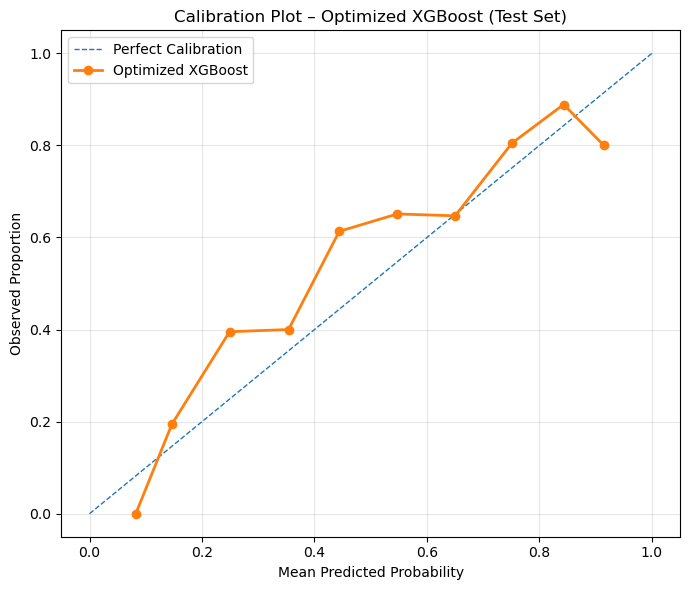

In [27]:
# ============================================================
# XGBOOST — TEST-SET CALIBRATION PLOT
# ============================================================

import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve

# Calculate calibration curve
prob_true_xgb, prob_pred_xgb = calibration_curve(
    y_test,
    xgb_test_prob,
    n_bins=10,
    strategy='uniform'
)

# ============================================================
# PLOT CALIBRATION CURVE
# ============================================================

plt.figure(figsize=(7, 6))

# Perfect calibration
plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    linewidth=1,
    label='Perfect Calibration'
)

# Optimized XGBoost
plt.plot(
    prob_pred_xgb,
    prob_true_xgb,
    marker='o',
    linewidth=2,
    label='Optimized XGBoost'
)

plt.xlabel('Mean Predicted Probability')
plt.ylabel('Observed Proportion')

plt.title(
    'Calibration Plot – Optimized XGBoost (Test Set)'
)

plt.legend(loc='upper left')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

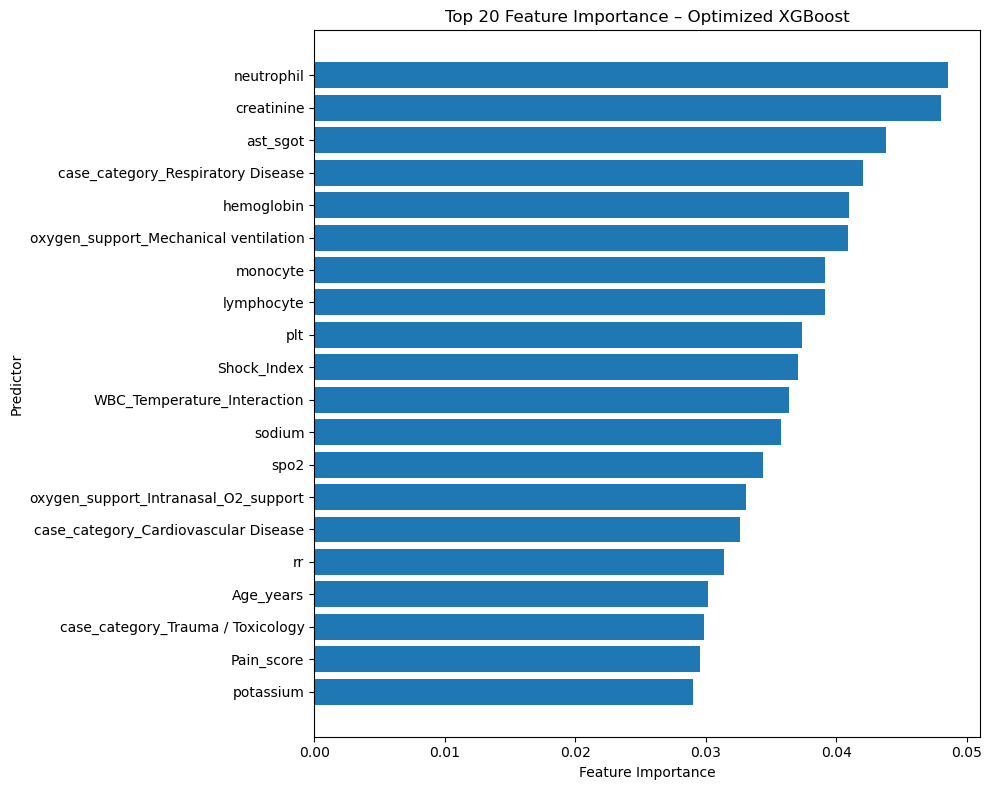

In [28]:
# ============================================================
# XGBOOST — FEATURE IMPORTANCE
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt

# Get feature importance
xgb_importance = xgb_model.feature_importances_

# Get feature names
xgb_feature_names = preprocessor.get_feature_names_out()

# Create DataFrame
xgb_feature_importance = pd.DataFrame({
    'Feature': xgb_feature_names,
    'Importance': xgb_importance
})

# ============================================================
# CLEAN FEATURE NAMES
# ============================================================

xgb_feature_importance['Feature'] = (
    xgb_feature_importance['Feature']
    
    # Remove categorical preprocessing prefix
    .str.replace(
        r'^categorical__',
        '',
        regex=True
    )
    
    # Remove mean/median preprocessing prefixes
    .str.replace(
        r'^(mean_num_|median_num_|categorical_mean_num_|categorical_median_num_)',
        '',
        regex=True
    )
    
    # Remove any remaining leading underscores
    .str.lstrip('_')
)

# ============================================================
# SORT FEATURES
# ============================================================

xgb_feature_importance = (
    xgb_feature_importance
    .sort_values(
        by='Importance',
        ascending=False
    )
    .reset_index(drop=True)
)

# Top 20 features
xgb_top20 = xgb_feature_importance.head(20)

# ============================================================
# PLOT
# ============================================================

plt.figure(figsize=(10, 8))

plt.barh(
    xgb_top20['Feature'][::-1],
    xgb_top20['Importance'][::-1]
)

plt.xlabel('Feature Importance')
plt.ylabel('Predictor')

plt.title(
    'Top 20 Feature Importance – Optimized XGBoost'
)

plt.tight_layout()
plt.show()

# Random forest model

In [18]:
from sklearn.ensemble import RandomForestClassifier

# ============================================================
# RANDOM FOREST MODEL — LOS PREDICTION
# ============================================================

rf_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=10,
    min_samples_split=10,
    min_samples_leaf=5,
    max_features='sqrt',
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

In [19]:
# ============================================================
# RANDOM FOREST HYPERPARAMETER SEARCH SPACE — LOS PREDICTION
# ============================================================

rf_param_grid = {

    'n_estimators': [
        300, 500, 800
    ],

    'max_depth': [
        5, 7, 8, 10, 12
    ],

    'min_samples_split': [
        10, 15, 20, 30
    ],

    'min_samples_leaf': [
        4, 6, 8, 10
    ],

    'max_features': [
        'sqrt', 'log2'
    ],

    'bootstrap': [
        True
    ],

    'criterion': [
        'gini', 'entropy'
    ]
}

In [20]:
# ============================================================
# RANDOMIZED HYPERPARAMETER SEARCH USING VALIDATION SET
# RANDOM FOREST — LOS PREDICTION
# ============================================================

import itertools
import random
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score

# ------------------------------------------------------------
# Generate all possible hyperparameter combinations
# ------------------------------------------------------------

rf_all_combinations = list(
    itertools.product(
        rf_param_grid['n_estimators'],
        rf_param_grid['max_depth'],
        rf_param_grid['min_samples_split'],
        rf_param_grid['min_samples_leaf'],
        rf_param_grid['max_features'],
        rf_param_grid['bootstrap'],
        rf_param_grid['criterion']
    )
)

# ------------------------------------------------------------
# Randomly select 50 combinations
# ------------------------------------------------------------

random.seed(42)

rf_sampled_combinations = random.sample(
    rf_all_combinations,
    50
)

print(
    f"Total possible combinations: "
    f"{len(rf_all_combinations):,}"
)

print(
    f"Randomly selected combinations: "
    f"{len(rf_sampled_combinations)}"
)

# ------------------------------------------------------------
# Evaluate each combination on training and validation sets
# ------------------------------------------------------------

rf_results = []

for combination in rf_sampled_combinations:

    rf_params = {
        'n_estimators': combination[0],
        'max_depth': combination[1],
        'min_samples_split': combination[2],
        'min_samples_leaf': combination[3],
        'max_features': combination[4],
        'bootstrap': combination[5],
        'criterion': combination[6]
    }

    rf_candidate = RandomForestClassifier(
        **rf_params,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    )

    # --------------------------------------------------------
    # Train ONLY on training data
    # --------------------------------------------------------

    rf_candidate.fit(
        X_train_processed,
        y_train
    )

    # --------------------------------------------------------
    # Training probabilities and AUC
    # --------------------------------------------------------

    rf_train_prob_candidate = rf_candidate.predict_proba(
        X_train_processed
    )[:, 1]

    rf_train_auc_candidate = roc_auc_score(
        y_train,
        rf_train_prob_candidate
    )

    # --------------------------------------------------------
    # Validation probabilities and AUC
    # --------------------------------------------------------

    rf_val_prob_candidate = rf_candidate.predict_proba(
        X_validation_processed
    )[:, 1]

    rf_val_auc_candidate = roc_auc_score(
        y_validation,
        rf_val_prob_candidate
    )

    # --------------------------------------------------------
    # Training-validation AUC gap
    # --------------------------------------------------------

    rf_auc_gap_candidate = (
        rf_train_auc_candidate -
        rf_val_auc_candidate
    )

    # --------------------------------------------------------
    # Store results
    # --------------------------------------------------------

    rf_results.append({
        **rf_params,
        'training_roc_auc': rf_train_auc_candidate,
        'validation_roc_auc': rf_val_auc_candidate,
        'auc_gap': rf_auc_gap_candidate
    })

# ------------------------------------------------------------
# Store and rank results
# ------------------------------------------------------------

rf_results_df = pd.DataFrame(
    rf_results
)

rf_results_df = rf_results_df.sort_values(
    by='validation_roc_auc',
    ascending=False
).reset_index(drop=True)

print("\nTop 10 Random Forest Hyperparameter Combinations:")

display(
    rf_results_df.head(10)
)

Total possible combinations: 960
Randomly selected combinations: 50

Top 10 Random Forest Hyperparameter Combinations:


,n_estimators,max_depth,min_samples_split,min_samples_leaf,max_features,bootstrap,criterion,training_roc_auc,validation_roc_auc,auc_gap
0,800,12,15,4,sqrt,True,entropy,0.976871,0.714915,0.261957
1,300,10,20,4,sqrt,True,entropy,0.947831,0.709654,0.238177
2,300,12,15,8,sqrt,True,entropy,0.957988,0.705437,0.252551
3,500,10,10,6,sqrt,True,entropy,0.954216,0.704839,0.249378
4,500,12,15,8,log2,True,entropy,0.954752,0.704471,0.250282
5,500,12,20,8,sqrt,True,gini,0.951866,0.704056,0.247810
6,500,12,15,10,sqrt,True,gini,0.942031,0.703535,0.238496
7,300,10,10,8,log2,True,entropy,0.936528,0.702599,0.233928
8,300,10,15,10,log2,True,entropy,0.921403,0.700667,0.220736
9,300,12,15,10,sqrt,True,gini,0.941291,0.700452,0.240838


In [21]:
# ============================================================
# SELECT BEST RANDOM FOREST HYPERPARAMETERS — LOS
# ============================================================

rf_best_row = rf_results_df.iloc[0]

rf_best_params = {
    'n_estimators': int(rf_best_row['n_estimators']),
    'max_depth': int(rf_best_row['max_depth']),
    'min_samples_split': int(rf_best_row['min_samples_split']),
    'min_samples_leaf': int(rf_best_row['min_samples_leaf']),
    'max_features': rf_best_row['max_features'],
    'bootstrap': bool(rf_best_row['bootstrap']),
    'criterion': rf_best_row['criterion']
}

rf_best_train_auc = rf_best_row['training_roc_auc']
rf_best_val_auc = rf_best_row['validation_roc_auc']
rf_best_auc_gap = rf_best_row['auc_gap']

print("Random Forest — Best Training ROC-AUC:")
print(f"{rf_best_train_auc:.4f}")

print("\nRandom Forest — Best Validation ROC-AUC:")
print(f"{rf_best_val_auc:.4f}")

print("\nRandom Forest — Training-Validation AUC Gap:")
print(f"{rf_best_auc_gap:.4f}")

print("\nRandom Forest — Best Parameters:")
for parameter, value in rf_best_params.items():
    print(f"  {parameter}: {value}")

Random Forest — Best Training ROC-AUC:
0.9769

Random Forest — Best Validation ROC-AUC:
0.7149

Random Forest — Training-Validation AUC Gap:
0.2620

Random Forest — Best Parameters:
  n_estimators: 800
  max_depth: 12
  min_samples_split: 15
  min_samples_leaf: 4
  max_features: sqrt
  bootstrap: True
  criterion: entropy


In [22]:
# ============================================================
# RANDOM FOREST — FINAL MODEL TRAINING FOR LOS
# ============================================================

from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    **rf_best_params,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

# Fit ONLY on the training dataset
rf_model.fit(
    X_train_processed,
    y_train
)

print("Random Forest model fitted successfully.")

Random Forest model fitted successfully.


In [23]:
# ============================================================
# RANDOM FOREST — FINAL TEST PERFORMANCE — LOS
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    brier_score_loss,
    confusion_matrix
)
import pandas as pd


# ============================================================
# 1. TEST-SET PREDICTIONS
# ============================================================

rf_test_pred = rf_model.predict(
    X_test_processed
)

rf_test_prob = rf_model.predict_proba(
    X_test_processed
)[:, 1]


# ============================================================
# 2. TRAINING AUC
# ============================================================

rf_train_prob = rf_model.predict_proba(
    X_train_processed
)[:, 1]

rf_train_auc = roc_auc_score(
    y_train,
    rf_train_prob
)


# ============================================================
# 3. TEST-SET METRICS
# ============================================================

rf_test_accuracy = accuracy_score(
    y_test,
    rf_test_pred
)

rf_test_precision = precision_score(
    y_test,
    rf_test_pred,
    zero_division=0
)

rf_test_recall = recall_score(
    y_test,
    rf_test_pred,
    zero_division=0
)

# Sensitivity = Recall
rf_test_sensitivity = rf_test_recall

rf_test_f1 = f1_score(
    y_test,
    rf_test_pred,
    zero_division=0
)

rf_test_roc_auc = roc_auc_score(
    y_test,
    rf_test_prob
)

rf_test_brier = brier_score_loss(
    y_test,
    rf_test_prob
)


# ============================================================
# 4. SPECIFICITY
# ============================================================

rf_test_tn, rf_test_fp, rf_test_fn, rf_test_tp = confusion_matrix(
    y_test,
    rf_test_pred,
    labels=[0, 1]
).ravel()

rf_test_specificity = rf_test_tn / (
    rf_test_tn + rf_test_fp
)


# ============================================================
# 5. AUC GAP
# ============================================================

rf_auc_gap = (
    rf_train_auc - rf_test_roc_auc
)


# ============================================================
# 6. CLASS-BASED TEST PERFORMANCE
# ============================================================

rf_class_metrics = pd.DataFrame({

    "LOS Class": [
        "≤7 days",
        ">7 days"
    ],

    "Precision": [
        precision_score(
            y_test,
            rf_test_pred,
            pos_label=0,
            zero_division=0
        ),
        precision_score(
            y_test,
            rf_test_pred,
            pos_label=1,
            zero_division=0
        )
    ],

    "Recall (Sensitivity)": [
        recall_score(
            y_test,
            rf_test_pred,
            pos_label=0,
            zero_division=0
        ),
        recall_score(
            y_test,
            rf_test_pred,
            pos_label=1,
            zero_division=0
        )
    ],

    "F1-score": [
        f1_score(
            y_test,
            rf_test_pred,
            pos_label=0,
            zero_division=0
        ),
        f1_score(
            y_test,
            rf_test_pred,
            pos_label=1,
            zero_division=0
        )
    ]
})


# ============================================================
# 7. DISPLAY OVERALL TEST PERFORMANCE
# ============================================================

print("\n" + "=" * 70)
print("RANDOM FOREST — FINAL TEST SET PERFORMANCE")
print("=" * 70)

print(f"Accuracy              : {rf_test_accuracy:.4f}")
print(f"Precision             : {rf_test_precision:.4f}")
print(f"Sensitivity           : {rf_test_sensitivity:.4f}")
print(f"Specificity           : {rf_test_specificity:.4f}")
print(f"F1-score              : {rf_test_f1:.4f}")
print(f"Training AUC          : {rf_train_auc:.4f}")
print(f"Test AUC              : {rf_test_roc_auc:.4f}")
print(f"AUC Gap (Train-Test)  : {rf_auc_gap:.4f}")
print(f"Brier Score           : {rf_test_brier:.4f}")


# ============================================================
# 8. DISPLAY CLASS-BASED TEST PERFORMANCE
# ============================================================

print("\n" + "=" * 70)
print("RANDOM FOREST — CLASS-BASED TEST PERFORMANCE")
print("=" * 70)

print(
    rf_class_metrics.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)


RANDOM FOREST — FINAL TEST SET PERFORMANCE
Accuracy              : 0.6845
Precision             : 0.7246
Sensitivity           : 0.7683
Specificity           : 0.5577
F1-score              : 0.7458
Training AUC          : 0.9769
Test AUC              : 0.7327
AUC Gap (Train-Test)  : 0.2442
Brier Score           : 0.2066

RANDOM FOREST — CLASS-BASED TEST PERFORMANCE
LOS Class  Precision  Recall (Sensitivity)  F1-score
  ≤7 days     0.6138                0.5577    0.5844
  >7 days     0.7246                0.7683    0.7458


# RANDOM FOREST MODEL FOR STREAMLIT — ICU LOS

In [26]:
# ============================================================
# SAVE FINAL RANDOM FOREST MODEL FOR STREAMLIT — ICU LOS
# ============================================================

import os
import joblib

# Destination folder
save_dir = r"C:\Users\pc\Downloads\manuscript"

# Create folder if it does not exist
os.makedirs(save_dir, exist_ok=True)

# Model save path
model_path = os.path.join(
    save_dir,
    "icu_los_random_forest.pkl"
)

# Save trained Random Forest model only
joblib.dump(rf_model, model_path)

print("=" * 60)
print("RANDOM FOREST MODEL SAVED SUCCESSFULLY")
print("=" * 60)
print(f"Model: Random Forest — ICU Length of Stay")
print(f"Location: {model_path}")
print(f"File exists: {os.path.exists(model_path)}")
print(f"File size: {os.path.getsize(model_path) / 1024:.2f} KB")

RANDOM FOREST MODEL SAVED SUCCESSFULLY
Model: Random Forest — ICU Length of Stay
Location: C:\Users\pc\Downloads\manuscript\icu_los_random_forest.pkl
File exists: True
File size: 16667.96 KB


In [26]:

# ============================================================
# SAVE RANDOM FOREST MODEL AND PREPROCESSOR — ICU LOS
# ============================================================

import os
import joblib

# Destination folder
save_dir = r"C:\Users\pc\Downloads\manuscript"

os.makedirs(save_dir, exist_ok=True)

# ------------------------------------------------------------
# 1. SAVE RANDOM FOREST MODEL
# ------------------------------------------------------------

model_path = os.path.join(
    save_dir,
    "icu_los_random_forest.pkl"
)

joblib.dump(rf_model, model_path)

# ------------------------------------------------------------
# 2. SAVE FITTED PREPROCESSOR
# ------------------------------------------------------------

preprocessor_path = os.path.join(
    save_dir,
    "preprocessor.pkl"
)

joblib.dump(preprocessor, preprocessor_path)

# ------------------------------------------------------------
# 3. VERIFY SAVED FILES
# ------------------------------------------------------------

print("=" * 65)
print("RANDOM FOREST MODEL AND PREPROCESSOR SAVED SUCCESSFULLY")
print("=" * 65)

for path in [model_path, preprocessor_path]:
    print(f"\nFile: {os.path.basename(path)}")
    print(f"Exists: {os.path.exists(path)}")

    if os.path.exists(path):
        print(f"Size: {os.path.getsize(path) / 1024:.2f} KB")

print("\nPreprocessor type:", type(preprocessor).__name__)
print("Training features:", X_train_processed.shape[1])
print("Save directory:", save_dir)



RANDOM FOREST MODEL AND PREPROCESSOR SAVED SUCCESSFULLY

File: icu_los_random_forest.pkl
Exists: True
Size: 16667.96 KB

File: preprocessor.pkl
Exists: True
Size: 6.18 KB

Preprocessor type: ColumnTransformer
Training features: 40
Save directory: C:\Users\pc\Downloads\manuscript


In [87]:
# ------------------------------------------------------------
# 95% Confidence Interval for ROC-AUC (Bootstrap)
# ------------------------------------------------------------

import numpy as np

y_test_array = np.asarray(y_test)
rf_test_prob_array = np.asarray(rf_test_prob)

rng = np.random.default_rng(42)

n_bootstraps = 5000
rf_bootstrap_auc = []

for i in range(n_bootstraps):

    indices = rng.integers(
        0,
        len(y_test_array),
        len(y_test_array)
    )

    y_boot = y_test_array[indices]
    prob_boot = rf_test_prob_array[indices]

    # Skip samples with only one class
    if len(np.unique(y_boot)) < 2:
        continue

    auc = roc_auc_score(
        y_boot,
        prob_boot
    )

    rf_bootstrap_auc.append(auc)

# 95% CI
rf_auc_ci_lower = np.percentile(
    rf_bootstrap_auc,
    2.5
)

rf_auc_ci_upper = np.percentile(
    rf_bootstrap_auc,
    97.5
)

In [88]:
print(
    f"ROC-AUC 95% CI : "
    f"{rf_auc_ci_lower:.4f} - {rf_auc_ci_upper:.4f}"
)

ROC-AUC 95% CI : 0.6875 - 0.7764


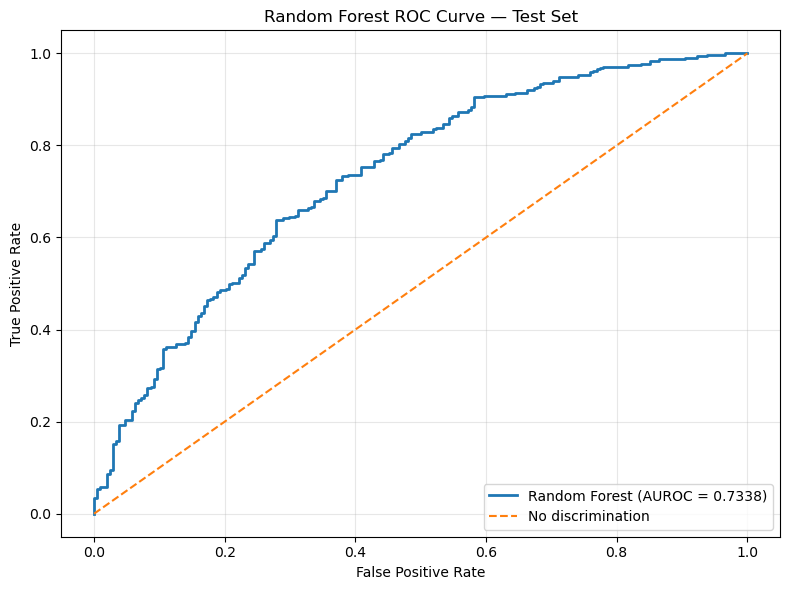

In [44]:
# ============================================================
# RANDOM FOREST — TEST-SET ROC CURVE
# ============================================================

import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

# Calculate ROC curve
rf_fpr, rf_tpr, rf_thresholds = roc_curve(
    y_test,
    rf_test_prob
)

# Calculate ROC-AUC
rf_test_roc_auc_curve = roc_auc_score(
    y_test,
    rf_test_prob
)

# Plot ROC curve
plt.figure(figsize=(8, 6))

plt.plot(
    rf_fpr,
    rf_tpr,
    linewidth=2,
    label=f'Random Forest (AUROC = {rf_test_roc_auc_curve:.4f})'
)

# No-discrimination reference line
plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    linewidth=1.5,
    label='No discrimination'
)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Random Forest ROC Curve — Test Set')

plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

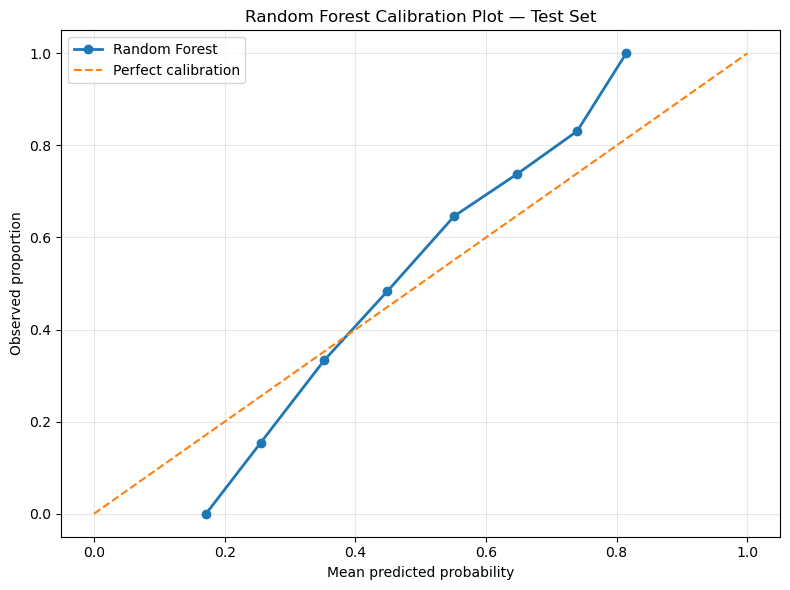

In [45]:
# ============================================================
# RANDOM FOREST — TEST-SET CALIBRATION PLOT
# ============================================================

import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve

# Calculate calibration curve
rf_prob_true, rf_prob_pred = calibration_curve(
    y_test,
    rf_test_prob,
    n_bins=10,
    strategy='uniform'
)

# Plot calibration curve
plt.figure(figsize=(8, 6))

plt.plot(
    rf_prob_pred,
    rf_prob_true,
    marker='o',
    linewidth=2,
    label='Random Forest'
)

# Perfect calibration reference line
plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    linewidth=1.5,
    label='Perfect calibration'
)

plt.xlabel('Mean predicted probability')
plt.ylabel('Observed proportion')
plt.title('Random Forest Calibration Plot — Test Set')

plt.legend(loc='upper left')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

===== RANDOM FOREST — TOP 20 FEATURE IMPORTANCES =====
                                         Feature  Importance
                                      neutrophil    0.068182
                                      lymphocyte    0.067248
                                             plt    0.067170
                                        monocyte    0.065107
                                      hemoglobin    0.064848
                     WBC_Temperature_Interaction    0.064617
                                     Shock_Index    0.064259
                                       potassium    0.053330
                                            spo2    0.051942
                                          sodium    0.049626
                                        ast_sgot    0.049518
                                             rbs    0.048845
                                             dbp    0.047233
                                       Age_years    0.047048
                              

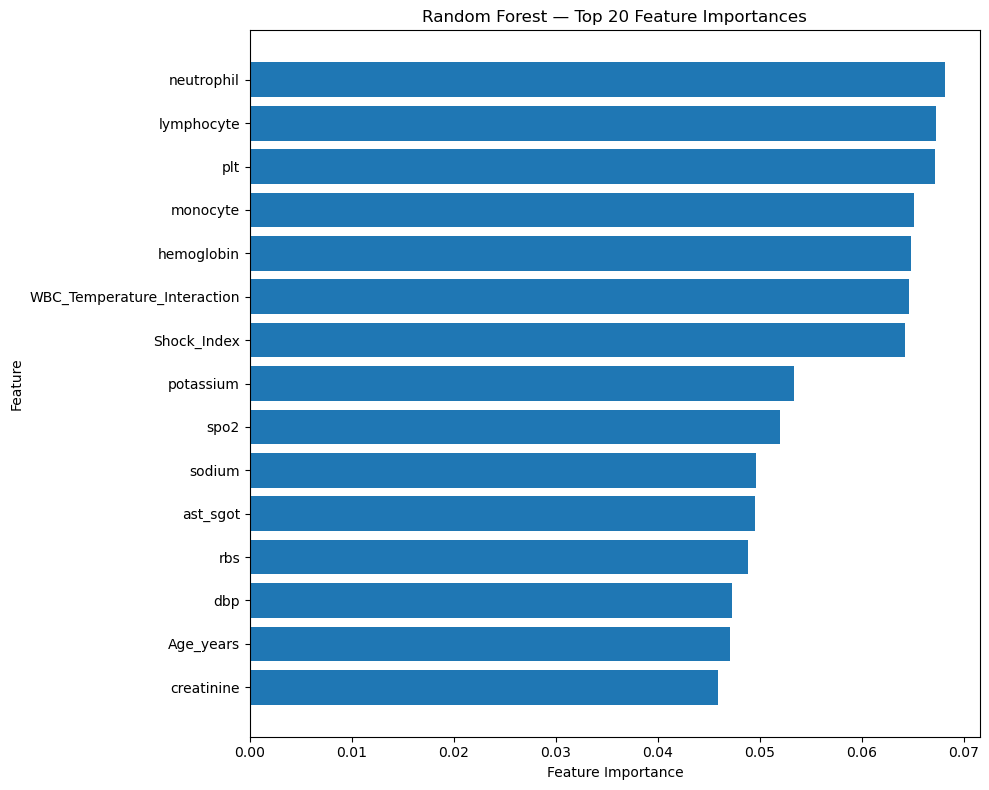

In [46]:
# ============================================================
# RANDOM FOREST — FEATURE IMPORTANCE
# CLEAN FEATURE NAMES FOR LOS PREDICTION
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# Get feature names from the fitted preprocessor
# ------------------------------------------------------------

feature_names = preprocessor.get_feature_names_out()

# ------------------------------------------------------------
# Remove ALL preprocessing prefixes
# Examples:
# mean__hr              -> hr
# median__creatinine    -> creatinine
# cat__Admission_source_Emergency -> Admission_source_Emergency
# ------------------------------------------------------------

clean_feature_names = []

for name in feature_names:

    # Remove everything before the last "__"
    if '__' in name:
        name = name.split('__')[-1]

    clean_feature_names.append(name)

# ------------------------------------------------------------
# Get Random Forest feature importance
# ------------------------------------------------------------

rf_importances = rf_model.feature_importances_

# ------------------------------------------------------------
# Create feature-importance DataFrame
# ------------------------------------------------------------

rf_feature_importance = pd.DataFrame({
    'Feature': clean_feature_names,
    'Importance': rf_importances
})

# Sort from highest to lowest
rf_feature_importance = rf_feature_importance.sort_values(
    by='Importance',
    ascending=False
).reset_index(drop=True)

# ============================================================
# TOP 20 FEATURES
# ============================================================

print("===== RANDOM FOREST — TOP 20 FEATURE IMPORTANCES =====")

print(
    rf_feature_importance
    .head(115)
    .to_string(index=False)
)

# ============================================================
# PLOT TOP 20 FEATURES
# ============================================================

top_features = (
    rf_feature_importance
    .head(15)
    .sort_values(
        by='Importance',
        ascending=True
    )
)

plt.figure(figsize=(10, 8))

plt.barh(
    top_features['Feature'],
    top_features['Importance']
)

plt.xlabel('Feature Importance')
plt.ylabel('Feature')
plt.title('Random Forest — Top 20 Feature Importances')

plt.tight_layout()
plt.show()


3-dimensional SHAP array detected.
Original SHAP shape: (522, 40, 2)


LOS SHAP DIMENSION CHECK
Processed data shape: (522, 40)
SHAP values shape:    (522, 40)
Dimension check: PASSED


RANDOM FOREST SHAP INTERPRETATION — TOP 15 VARIABLES
OUTCOME: LOS >7 DAYS
 Rank                               Feature  Mean_ABS_SHAP  Mean_SHAP  Positive_SHAP_%  Negative_SHAP_%                           Overall_direction
    1                            neutrophil         0.0300     0.0037          47.1264          52.8736 Higher predicted probability of LOS >7 days
    2                            hemoglobin         0.0274     0.0036          37.7395          62.2605 Higher predicted probability of LOS >7 days
    3                            creatinine         0.0258     0.0007          33.1418          66.8582 Higher predicted probability of LOS >7 days
    4                           Shock_Index         0.0221     0.0050          81.0345          18.9655 Higher predicted probability of LOS >7 days

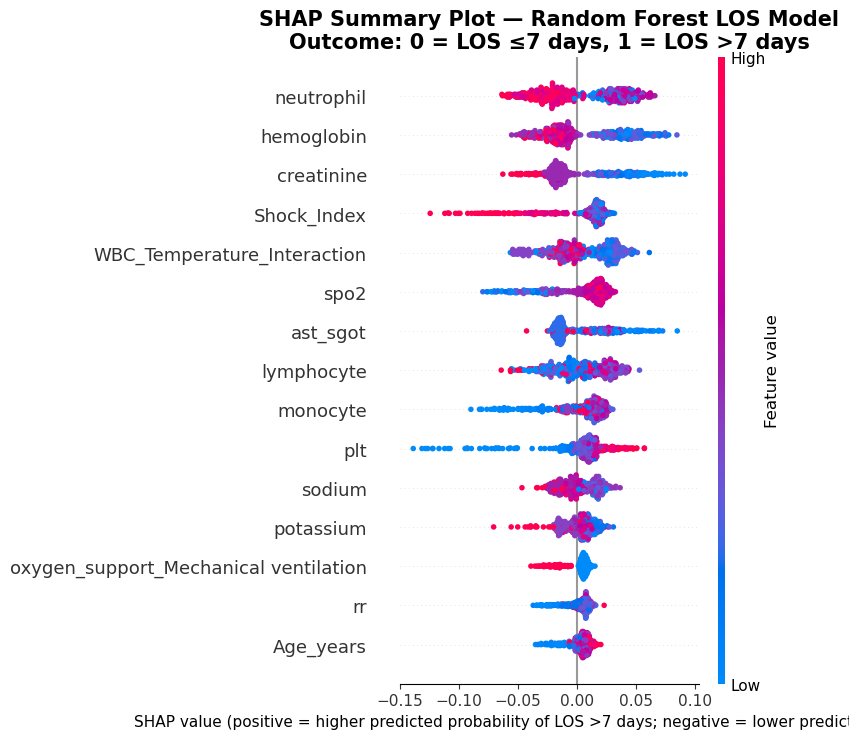



COMPLETED

Outcome:
0 = LOS ≤7 days
1 = LOS >7 days

Positive SHAP = higher predicted probability of LOS >7 days
Negative SHAP = lower predicted probability of LOS >7 days

Top 15 variables saved:
RandomForest_LOS_SHAP_Top15_Interpretation.csv


In [47]:
# ============================================================
# RANDOM FOREST SHAP INTERPRETATION — LOS
# TOP 15 VARIABLES
#
# TARGET:
#   0 = LOS ≤ 7 days
#   1 = LOS > 7 days
#
# SHAP:
#   Positive SHAP → higher predicted probability of LOS >7 days
#   Negative SHAP → lower predicted probability of LOS >7 days
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap


# ============================================================
# 1. VALIDATION DATA
# ============================================================

X_shap = np.asarray(
    X_validation_processed
)


# ============================================================
# 2. FEATURE NAMES
# ============================================================

feature_names = (
    preprocessor.get_feature_names_out()
)


# ============================================================
# 3. CLEAN FEATURE NAMES
# ============================================================

clean_names = []

for name in feature_names:

    if "__" in name:
        name = name.split("__")[-1]

    clean_names.append(name)


# ============================================================
# 4. CREATE DATAFRAME
# ============================================================

X_shap_df = pd.DataFrame(
    X_shap,
    columns=clean_names
)


# ============================================================
# 5. SHAP EXPLAINER
# ============================================================

explainer = shap.TreeExplainer(
    rf_model
)


# ============================================================
# 6. CALCULATE SHAP VALUES
# ============================================================

shap_values = explainer.shap_values(
    X_shap_df
)


# ============================================================
# 7. SELECT CLASS 1
#
# 0 = LOS ≤7 days
# 1 = LOS >7 days
#
# Therefore we explain CLASS 1.
# ============================================================

if isinstance(shap_values, list):

    print(
        "\nSHAP output detected as a list."
    )

    print(
        f"Number of classes: {len(shap_values)}"
    )

    # Class 1 = LOS >7 days

    shap_values = shap_values[1]


elif (
    isinstance(shap_values, np.ndarray)
    and shap_values.ndim == 3
):

    print(
        "\n3-dimensional SHAP array detected."
    )

    print(
        f"Original SHAP shape: {shap_values.shape}"
    )

    # Class 1 = LOS >7 days

    shap_values = shap_values[:, :, 1]


shap_values = np.asarray(
    shap_values
)


# ============================================================
# 8. CHECK DIMENSIONS
# ============================================================

print("\n")
print("=" * 100)
print("LOS SHAP DIMENSION CHECK")
print("=" * 100)

print(
    f"Processed data shape: {X_shap.shape}"
)

print(
    f"SHAP values shape:    {shap_values.shape}"
)


if shap_values.shape != X_shap.shape:

    raise ValueError(
        "SHAP dimensions do not match "
        "the processed data."
    )


print(
    "Dimension check: PASSED"
)

print("=" * 100)


# ============================================================
# 9. CALCULATE SHAP IMPORTANCE
# ============================================================

mean_abs_shap = np.abs(
    shap_values
).mean(axis=0)


mean_shap = shap_values.mean(
    axis=0
)


# ============================================================
# 10. CREATE IMPORTANCE TABLE
# ============================================================

importance_df = pd.DataFrame({

    "Feature":
        clean_names,

    "Mean_ABS_SHAP":
        mean_abs_shap,

    "Mean_SHAP":
        mean_shap

})


# ============================================================
# 11. SORT AND SELECT TOP 15
# ============================================================

importance_df = (
    importance_df
    .sort_values(
        "Mean_ABS_SHAP",
        ascending=False
    )
    .reset_index(drop=True)
)


top15 = importance_df.head(
    15
).copy()


# ============================================================
# 12. CALCULATE DIRECTION
# ============================================================

directions = []

positive_percent = []

negative_percent = []


for feature in top15["Feature"]:

    index = clean_names.index(
        feature
    )

    values = shap_values[:, index]

    positive = np.sum(
        values > 0
    )

    negative = np.sum(
        values < 0
    )

    total = len(values)

    positive_pct = (
        positive / total
    ) * 100

    negative_pct = (
        negative / total
    ) * 100

    positive_percent.append(
        positive_pct
    )

    negative_percent.append(
        negative_pct
    )

    # --------------------------------------------------------
    # Direction
    #
    # Positive SHAP = higher probability of LOS >7 days
    # Negative SHAP = lower probability of LOS >7 days
    # --------------------------------------------------------

    mean_value = np.mean(
        values
    )

    if mean_value > 0:

        direction = (
            "Higher predicted probability of LOS >7 days"
        )

    elif mean_value < 0:

        direction = (
            "Lower predicted probability of LOS >7 days"
        )

    else:

        direction = (
            "Mixed / neutral"
        )

    directions.append(
        direction
    )


# ============================================================
# 13. CREATE FINAL TOP 15 TABLE
# ============================================================

interpretation_df = pd.DataFrame({

    "Rank":
        np.arange(1, 16),

    "Feature":
        top15["Feature"].values,

    "Mean_ABS_SHAP":
        top15["Mean_ABS_SHAP"].values,

    "Mean_SHAP":
        top15["Mean_SHAP"].values,

    "Positive_SHAP_%":
        positive_percent,

    "Negative_SHAP_%":
        negative_percent,

    "Overall_direction":
        directions

})


# ============================================================
# 14. PRINT RESULTS
# ============================================================

print("\n")
print("=" * 110)

print(
    "RANDOM FOREST SHAP INTERPRETATION — TOP 15 VARIABLES"
)

print(
    "OUTCOME: LOS >7 DAYS"
)

print("=" * 110)

print(
    interpretation_df
    .round(4)
    .to_string(index=False)
)

print("=" * 110)


# ============================================================
# 15. THESIS INTERPRETATION
# ============================================================

print("\n")
print("=" * 110)

print(
    "INTERPRETATION FOR THESIS"
)

print("=" * 110)

print(
    "\nTarget coding:"
)

print(
    "  0 = LOS ≤7 days"
)

print(
    "  1 = LOS >7 days"
)

print(
    "\nSHAP interpretation:"
)

print(
    "  Positive SHAP → higher predicted probability of LOS >7 days"
)

print(
    "  Negative SHAP → lower predicted probability of LOS >7 days"
)


for _, row in interpretation_df.iterrows():

    print(
        f"\n{int(row['Rank'])}. {row['Feature']}"
    )

    print(
        f"   Mean absolute SHAP: "
        f"{row['Mean_ABS_SHAP']:.4f}"
    )

    print(
        f"   Mean SHAP: "
        f"{row['Mean_SHAP']:.4f}"
    )

    print(
        f"   Positive SHAP: "
        f"{row['Positive_SHAP_%']:.1f}% "
        f"(toward LOS >7 days)"
    )

    print(
        f"   Negative SHAP: "
        f"{row['Negative_SHAP_%']:.1f}% "
        f"(toward LOS ≤7 days)"
    )

    print(
        f"   Overall model contribution: "
        f"{row['Overall_direction']}"
    )


print("\n")
print("=" * 110)


# ============================================================
# 16. SHAP BEESWARM — TOP 15
# ============================================================

plt.figure(
    figsize=(11, 8)
)


shap.summary_plot(

    shap_values,

    X_shap_df,

    plot_type="dot",

    max_display=15,

    color_bar=True,

    show=False

)


plt.title(

    "SHAP Summary Plot — Random Forest LOS Model\n"
    "Outcome: 0 = LOS ≤7 days, 1 = LOS >7 days",

    fontsize=15,

    fontweight="bold"

)


plt.xlabel(

    "SHAP value "
    "(positive = higher predicted probability of LOS >7 days; "
    "negative = lower predicted probability)",

    fontsize=11

)


plt.tight_layout()


# ============================================================
# 17. SAVE FIGURES
# ============================================================

plt.savefig(

    "RandomForest_LOS_SHAP_Top15.png",

    dpi=600,

    bbox_inches="tight"

)


plt.savefig(

    "RandomForest_LOS_SHAP_Top15.pdf",

    bbox_inches="tight"

)


plt.show()


# ============================================================
# 18. SAVE TABLE
# ============================================================

interpretation_df.to_csv(

    "RandomForest_LOS_SHAP_Top15_Interpretation.csv",

    index=False

)


# ============================================================
# 19. COMPLETION
# ============================================================

print("\n")
print("=" * 110)

print("COMPLETED")

print("=" * 110)

print(
    "\nOutcome:"
)

print(
    "0 = LOS ≤7 days"
)

print(
    "1 = LOS >7 days"
)

print(
    "\nPositive SHAP = higher predicted probability of LOS >7 days"
)

print(
    "Negative SHAP = lower predicted probability of LOS >7 days"
)

print(
    "\nTop 15 variables saved:"
)

print(
    "RandomForest_LOS_SHAP_Top15_Interpretation.csv"
)

print("=" * 110)

# Support vector Machine

In [35]:
from sklearn.preprocessing import StandardScaler

# ============================================================
# STANDARDIZATION FOR SVM AND LOGISTIC REGRESSION
# ============================================================

# Initialize scaler
scaler = StandardScaler()

# ------------------------------------------------------------
# 1. FIT SCALER ONLY ON TRAINING DATA
# ------------------------------------------------------------
X_train_scaled = scaler.fit_transform(X_train_processed)

# ------------------------------------------------------------
# 2. APPLY TRAINING-LEARNED SCALER TO VALIDATION DATA
# ------------------------------------------------------------
X_validation_scaled = scaler.transform(X_validation_processed)

# ------------------------------------------------------------
# 3. APPLY TRAINING-LEARNED SCALER TO TEST DATA
# ------------------------------------------------------------
X_test_scaled = scaler.transform(X_test_processed)

# ============================================================
# CHECK SHAPES
# ============================================================

print("Standardized dataset shapes:")
print("-" * 45)
print("Training   :", X_train_scaled.shape)
print("Validation :", X_validation_scaled.shape)
print("Test       :", X_test_scaled.shape)

Standardized dataset shapes:
---------------------------------------------
Training   : (2437, 40)
Validation : (522, 40)
Test       : (523, 40)


In [36]:
# ============================================================
# SUPPORT VECTOR MACHINE (SVM) — MODEL DEFINITION
# ============================================================

from sklearn.svm import SVC

svm_model = SVC(
    probability=True,
    class_weight='balanced',
    random_state=42
)

print(svm_model)

SVC(class_weight='balanced', probability=True, random_state=42)


In [37]:
# SVM — HYPERPARAMETER SEARCH SPACE
svm_param_grid = {
    'C': [
        0.01,
        0.1,
        1,
        10,
        100
    ],

    'gamma': [
        'scale',
        0.001,
        0.01,
        0.1,
        1
    ],

    'kernel': [
        'rbf'
    ]
}

print("SVM hyperparameter search space:")
print(svm_param_grid)

SVM hyperparameter search space:
{'C': [0.01, 0.1, 1, 10, 100], 'gamma': ['scale', 0.001, 0.01, 0.1, 1], 'kernel': ['rbf']}


In [38]:
# ============================================================
# SVM — HYPERPARAMETER TUNING USING VALIDATION SET
# ============================================================

from sklearn.svm import SVC
from sklearn.metrics import roc_auc_score
from itertools import product
import pandas as pd


# ============================================================
# 1. GENERATE PARAMETER COMBINATIONS
# ============================================================

param_combinations = list(product(
    svm_param_grid['C'],
    svm_param_grid['gamma'],
    svm_param_grid['kernel']
))


# ============================================================
# 2. EVALUATE EACH COMBINATION
# ============================================================

svm_results = []

for C, gamma, kernel in param_combinations:

    svm_candidate = SVC(
        C=C,
        gamma=gamma,
        kernel=kernel,
        probability=True,
        class_weight='balanced',
        random_state=42
    )

    # Fit ONLY on training data
    svm_candidate.fit(
        X_train_scaled,
        y_train
    )

    # Predict probabilities on validation data
    y_validation_prob = svm_candidate.predict_proba(
        X_validation_scaled
    )[:, 1]

    # Validation ROC-AUC
    validation_auc = roc_auc_score(
        y_validation,
        y_validation_prob
    )

    svm_results.append({
        'C': C,
        'gamma': gamma,
        'kernel': kernel,
        'Validation_ROC_AUC': validation_auc
    })


# ============================================================
# 3. RESULTS TABLE
# ============================================================

svm_results_df = pd.DataFrame(svm_results)

svm_results_df = svm_results_df.sort_values(
    by='Validation_ROC_AUC',
    ascending=False
).reset_index(drop=True)


print("SVM hyperparameter tuning results:")
print(svm_results_df)


# ============================================================
# 4. BEST HYPERPARAMETERS
# ============================================================

best_svm_params = svm_results_df.iloc[0].to_dict()

print("\nBest SVM hyperparameters:")
print("C     :", best_svm_params['C'])
print("gamma :", best_svm_params['gamma'])
print("kernel:", best_svm_params['kernel'])
print("Validation ROC-AUC:", best_svm_params['Validation_ROC_AUC'])

SVM hyperparameter tuning results:
         C  gamma kernel  Validation_ROC_AUC
0   100.00  0.001    rbf            0.673844
1     1.00   0.01    rbf            0.671421
2     1.00  scale    rbf            0.670125
3    10.00  0.001    rbf            0.660885
4    10.00   0.01    rbf            0.658830
5     1.00  0.001    rbf            0.655042
6     1.00    0.1    rbf            0.653393
7     0.10   0.01    rbf            0.652251
8     0.10  scale    rbf            0.649429
9    10.00  scale    rbf            0.644414
10  100.00   0.01    rbf            0.640833
11    0.10  0.001    rbf            0.637666
12    0.10    0.1    rbf            0.634721
13   10.00    0.1    rbf            0.625213
14  100.00    0.1    rbf            0.624852
15  100.00  scale    rbf            0.622475
16    1.00      1    rbf            0.602262
17  100.00      1    rbf            0.602231
18   10.00      1    rbf            0.602231
19    0.01      1    rbf            0.397508
20    0.10      1   

In [39]:
# ============================================================
# SVM — FINAL MODEL WITH BEST HYPERPARAMETERS
# ============================================================

from sklearn.svm import SVC

# Get best parameters
best_C = svm_results_df.loc[0, 'C']
best_gamma = svm_results_df.loc[0, 'gamma']
best_kernel = svm_results_df.loc[0, 'kernel']

# Create final SVM
svm_final_model = SVC(
    C=best_C,
    gamma=best_gamma,
    kernel=best_kernel,
    probability=True,
    class_weight='balanced',
    random_state=42
)

# ============================================================
# FIT FINAL SVM ON TRAINING DATA
# ============================================================

svm_final_model.fit(
    X_train_scaled,
    y_train
)

print("Final SVM model fitted successfully.")
print("Best C     :", best_C)
print("Best gamma :", best_gamma)
print("Best kernel:", best_kernel)

Final SVM model fitted successfully.
Best C     : 100.0
Best gamma : 0.001
Best kernel: rbf


In [40]:
# ============================================================
# SVM — FINAL TEST PERFORMANCE
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)
import pandas as pd


# ============================================================
# TEST PREDICTIONS
# ============================================================

y_test_pred = svm_final_model.predict(
    X_test_scaled
)

y_test_prob = svm_final_model.predict_proba(
    X_test_scaled
)[:, 1]


# ============================================================
# TRAINING AUC
# ============================================================

y_train_prob = svm_final_model.predict_proba(
    X_train_scaled
)[:, 1]

train_auc = roc_auc_score(
    y_train,
    y_train_prob
)


# ============================================================
# TEST AUC
# ============================================================

test_auc = roc_auc_score(
    y_test,
    y_test_prob
)


# ============================================================
# AUC GAP
# ============================================================

auc_gap = train_auc - test_auc


# ============================================================
# OVERALL TEST METRICS
# ============================================================

accuracy = accuracy_score(
    y_test,
    y_test_pred
)

precision = precision_score(
    y_test,
    y_test_pred,
    zero_division=0
)

recall = recall_score(
    y_test,
    y_test_pred,
    zero_division=0
)

sensitivity = recall

f1 = f1_score(
    y_test,
    y_test_pred,
    zero_division=0
)


# ============================================================
# SPECIFICITY
# ============================================================

tn, fp, fn, tp = confusion_matrix(
    y_test,
    y_test_pred,
    labels=[0, 1]
).ravel()

specificity = tn / (tn + fp)


# ============================================================
# CLASS-BASED PERFORMANCE
# ============================================================

class_metrics = pd.DataFrame({
    "Class": ["≤7 days", ">7 days"],

    "Precision": [
        precision_score(
            y_test,
            y_test_pred,
            pos_label=0,
            zero_division=0
        ),
        precision_score(
            y_test,
            y_test_pred,
            pos_label=1,
            zero_division=0
        )
    ],

    "Recall (Sensitivity)": [
        recall_score(
            y_test,
            y_test_pred,
            pos_label=0,
            zero_division=0
        ),
        recall_score(
            y_test,
            y_test_pred,
            pos_label=1,
            zero_division=0
        )
    ],

    "F1-score": [
        f1_score(
            y_test,
            y_test_pred,
            pos_label=0,
            zero_division=0
        ),
        f1_score(
            y_test,
            y_test_pred,
            pos_label=1,
            zero_division=0
        )
    ]
})


# ============================================================
# DISPLAY OVERALL PERFORMANCE
# ============================================================

print("\n" + "=" * 65)
print("SVM — FINAL TEST PERFORMANCE")
print("=" * 65)

print(f"Accuracy              : {accuracy:.4f}")
print(f"Precision             : {precision:.4f}")
print(f"Sensitivity           : {sensitivity:.4f}")
print(f"Specificity           : {specificity:.4f}")
print(f"F1-score              : {f1:.4f}")
print(f"Training AUC          : {train_auc:.4f}")
print(f"Test AUC              : {test_auc:.4f}")
print(f"AUC Gap (Train-Test)  : {auc_gap:.4f}")


# ============================================================
# DISPLAY CLASS-BASED PERFORMANCE
# ============================================================

print("\n" + "=" * 65)
print("CLASS-BASED TEST PERFORMANCE")
print("=" * 65)

print(
    class_metrics.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)


SVM — FINAL TEST PERFORMANCE
Accuracy              : 0.6405
Precision             : 0.6966
Sensitivity           : 0.7143
Specificity           : 0.5288
F1-score              : 0.7053
Training AUC          : 0.7556
Test AUC              : 0.6684
AUC Gap (Train-Test)  : 0.0872

CLASS-BASED TEST PERFORMANCE
  Class  Precision  Recall (Sensitivity)  F1-score
≤7 days     0.5500                0.5288    0.5392
>7 days     0.6966                0.7143    0.7053


# logistic regresion

In [41]:
# ============================================================
# LOGISTIC REGRESSION — MODEL DEFINITION
# ============================================================

from sklearn.linear_model import LogisticRegression

logreg = LogisticRegression(
    penalty='l2',
    solver='liblinear',
    class_weight='balanced',
    max_iter=2000,
    random_state=42
)

print(logreg)

LogisticRegression(class_weight='balanced', max_iter=2000, random_state=42,
                   solver='liblinear')


In [42]:
# ============================================================
# LOGISTIC REGRESSION — FIT MODEL ON TRAINING DATA
# ============================================================

logreg.fit(
    X_train_scaled,
    y_train
)

print("Logistic Regression model fitted successfully.")

Logistic Regression model fitted successfully.


In [43]:
# ============================================================
# LOGISTIC REGRESSION — HYPERPARAMETER SEARCH SPACE
# ============================================================

logreg_param_grid = {
    'C': [
        0.01,
        0.1,
        1,
        10,
        100
    ]
}

print("Logistic Regression hyperparameter search space:")
print(logreg_param_grid)

Logistic Regression hyperparameter search space:
{'C': [0.01, 0.1, 1, 10, 100]}


In [44]:
# ============================================================
# LOGISTIC REGRESSION — HYPERPARAMETER OPTIMIZATION
#              TRAIN → VALIDATION
# ============================================================

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
import pandas as pd

logreg_results = []

for C_value in logreg_param_grid['C']:

    logreg_candidate = LogisticRegression(
        penalty='l2',
        solver='liblinear',
        C=C_value,
        class_weight='balanced',
        max_iter=2000,
        random_state=42
    )

    # Fit on training data
    logreg_candidate.fit(
        X_train_scaled,
        y_train
    )

    # Predict probabilities on validation data
    y_validation_prob = logreg_candidate.predict_proba(
        X_validation_scaled
    )[:, 1]

    # Validation ROC-AUC
    validation_auc = roc_auc_score(
        y_validation,
        y_validation_prob
    )

    logreg_results.append({
        'C': C_value,
        'Validation_ROC_AUC': validation_auc
    })

# Convert results to DataFrame
logreg_results_df = pd.DataFrame(logreg_results)

# Rank by validation ROC-AUC
logreg_results_df = logreg_results_df.sort_values(
    by='Validation_ROC_AUC',
    ascending=False
).reset_index(drop=True)

print("Logistic Regression hyperparameter tuning results:")
print(logreg_results_df)

# Best hyperparameter
best_logreg_C = logreg_results_df.loc[0, 'C']

print("\nBest Logistic Regression hyperparameter:")
print("C:", best_logreg_C)
print(
    "Validation ROC-AUC:",
    f"{logreg_results_df.loc[0, 'Validation_ROC_AUC']:.4f}"
)

Logistic Regression hyperparameter tuning results:
        C  Validation_ROC_AUC
0    0.10            0.657082
1    0.01            0.656391
2    1.00            0.656023
3   10.00            0.655487
4  100.00            0.655349

Best Logistic Regression hyperparameter:
C: 0.1
Validation ROC-AUC: 0.6571


In [45]:
# ============================================================
# LOGISTIC REGRESSION — FIT BEST MODEL ON TRAINING DATA
# ============================================================

best_logreg = LogisticRegression(
    penalty='l2',
    solver='liblinear',
    C=best_logreg_C,
    class_weight='balanced',
    max_iter=2000,
    random_state=42
)

best_logreg.fit(
    X_train_scaled,
    y_train
)

print("Best Logistic Regression model fitted successfully.")

Best Logistic Regression model fitted successfully.


In [46]:
# ============================================================
# LOGISTIC REGRESSION — VALIDATION SET PREDICTIONS
# ============================================================

logreg_validation_y_pred = best_logreg.predict(
    X_validation_scaled
)

# Probability of mortality
logreg_validation_y_prob = best_logreg.predict_proba(
    X_validation_scaled
)[:, 1]

print("Validation predictions generated successfully.")

Validation predictions generated successfully.


In [47]:
# ============================================================
# LOGISTIC REGRESSION — FINAL MODEL AND TEST PERFORMANCE
# ============================================================

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)
import pandas as pd


# ============================================================
# 1. CREATE FINAL LOGISTIC REGRESSION MODEL
# ============================================================

best_logreg = LogisticRegression(
    penalty='l2',
    solver='liblinear',
    C=best_logreg_C,
    class_weight='balanced',
    max_iter=2000,
    random_state=42
)

# Fit on training data
best_logreg.fit(
    X_train_scaled,
    y_train
)

print("Final Logistic Regression model fitted successfully.")
print("Best C:", best_logreg_C)


# ============================================================
# 2. TRAINING AUC
# ============================================================

logreg_train_y_prob = best_logreg.predict_proba(
    X_train_scaled
)[:, 1]

train_auc = roc_auc_score(
    y_train,
    logreg_train_y_prob
)


# ============================================================
# 3. FINAL TEST SET PREDICTIONS
# ============================================================

logreg_test_y_pred = best_logreg.predict(
    X_test_scaled
)

logreg_test_y_prob = best_logreg.predict_proba(
    X_test_scaled
)[:, 1]


# ============================================================
# 4. OVERALL TEST SET PERFORMANCE
# ============================================================

test_accuracy = accuracy_score(
    y_test,
    logreg_test_y_pred
)

test_precision = precision_score(
    y_test,
    logreg_test_y_pred,
    zero_division=0
)

test_recall = recall_score(
    y_test,
    logreg_test_y_pred,
    zero_division=0
)

# Recall = Sensitivity
test_sensitivity = test_recall

test_f1 = f1_score(
    y_test,
    logreg_test_y_pred,
    zero_division=0
)

test_roc_auc = roc_auc_score(
    y_test,
    logreg_test_y_prob
)


# ============================================================
# 5. SPECIFICITY
# ============================================================

tn, fp, fn, tp = confusion_matrix(
    y_test,
    logreg_test_y_pred,
    labels=[0, 1]
).ravel()

test_specificity = tn / (tn + fp)


# ============================================================
# 6. AUC GAP: TRAINING AUC - TEST AUC
# ============================================================

auc_gap = train_auc - test_roc_auc


# ============================================================
# 7. CLASS-BASED TEST PERFORMANCE
# ============================================================

class_metrics = pd.DataFrame({
    "LOS Class": ["≤7 days", ">7 days"],

    "Precision": [
        precision_score(
            y_test,
            logreg_test_y_pred,
            pos_label=0,
            zero_division=0
        ),
        precision_score(
            y_test,
            logreg_test_y_pred,
            pos_label=1,
            zero_division=0
        )
    ],

    "Recall (Sensitivity)": [
        recall_score(
            y_test,
            logreg_test_y_pred,
            pos_label=0,
            zero_division=0
        ),
        recall_score(
            y_test,
            logreg_test_y_pred,
            pos_label=1,
            zero_division=0
        )
    ],

    "F1-score": [
        f1_score(
            y_test,
            logreg_test_y_pred,
            pos_label=0,
            zero_division=0
        ),
        f1_score(
            y_test,
            logreg_test_y_pred,
            pos_label=1,
            zero_division=0
        )
    ]
})


# ============================================================
# 8. DISPLAY FINAL TEST PERFORMANCE
# ============================================================

print("\n" + "=" * 65)
print("LOGISTIC REGRESSION — FINAL TEST SET PERFORMANCE")
print("=" * 65)

print(f"Accuracy              : {test_accuracy:.4f}")
print(f"Precision             : {test_precision:.4f}")
print(f"Sensitivity           : {test_sensitivity:.4f}")
print(f"Specificity           : {test_specificity:.4f}")
print(f"F1-score              : {test_f1:.4f}")
print(f"Training AUC          : {train_auc:.4f}")
print(f"Test AUC              : {test_roc_auc:.4f}")
print(f"AUC Gap (Train-Test)  : {auc_gap:.4f}")


# ============================================================
# 9. DISPLAY CLASS-BASED TEST PERFORMANCE
# ============================================================

print("\n" + "=" * 65)
print("LOGISTIC REGRESSION — CLASS-BASED TEST PERFORMANCE")
print("=" * 65)

print(
    class_metrics.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

Final Logistic Regression model fitted successfully.
Best C: 0.1

LOGISTIC REGRESSION — FINAL TEST SET PERFORMANCE
Accuracy              : 0.6099
Precision             : 0.6894
Sensitivity           : 0.6413
Specificity           : 0.5625
F1-score              : 0.6645
Training AUC          : 0.6562
Test AUC              : 0.6445
AUC Gap (Train-Test)  : 0.0117

LOGISTIC REGRESSION — CLASS-BASED TEST PERFORMANCE
LOS Class  Precision  Recall (Sensitivity)  F1-score
  ≤7 days     0.5087                0.5625    0.5342
  >7 days     0.6894                0.6413    0.6645


LOGISTIC REGRESSION — TOP 20 FEATURE IMPORTANCE
                              Feature  Coefficient  Importance
                           creatinine    -0.210200    0.210200
                          Shock_Index    -0.207427    0.207427
                                  plt     0.194432    0.194432
                           neutrophil    -0.180693    0.180693
   case_category_Neurological Disease     0.174095    0.174095
    case_category_Trauma / Toxicology     0.171991    0.171991
                                 spo2     0.154178    0.154178
                           lymphocyte    -0.147861    0.147861
        case_category_Thromboembolism     0.139669    0.139669
                           hemoglobin    -0.133646    0.133646
oxygen_support_Mechanical ventilation    -0.123752    0.123752
     case_category_Sepsis / Infection     0.117382    0.117382
                                  dbp    -0.108129    0.108129
 oxygen_support_Intranasal_O2_support     0.093688    0.093688
       

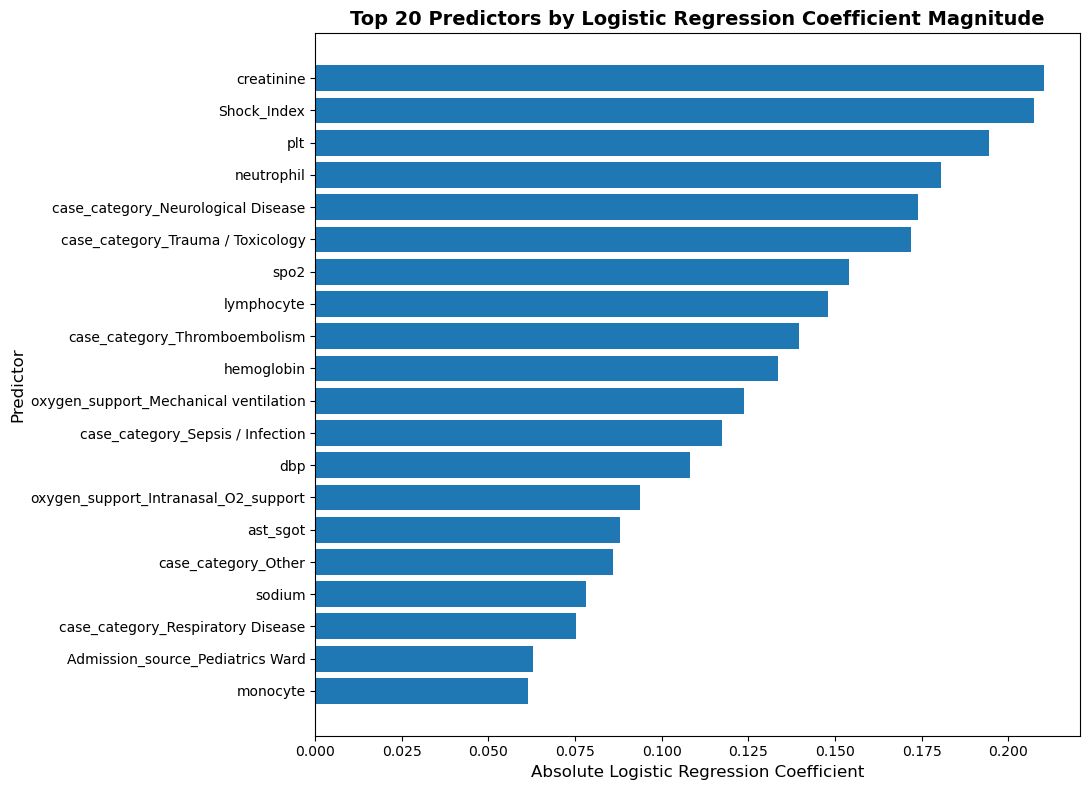

In [48]:
# ============================================================
# LOGISTIC REGRESSION — FEATURE IMPORTANCE (TOP 20)
# Advanced version: automatically removes preprocessing prefixes
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re

# ============================================================
# 1. EXTRACT COEFFICIENTS AND FEATURE NAMES
# ============================================================

coefficients = best_logreg.coef_[0]

feature_names = preprocessor.get_feature_names_out()

# Create feature importance dataframe
logreg_importance = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': coefficients
})

# Absolute coefficient = importance
logreg_importance['Importance'] = (
    logreg_importance['Coefficient'].abs()
)


# ============================================================
# 2. REMOVE ALL PREPROCESSING PREFIXES
# ============================================================

def clean_feature_name(feature):
    """
    Remove preprocessing/pipeline prefixes while preserving
    the actual clinical variable and categorical level.
    """

    # Remove everything before the final "__"
    # Examples:
    # mean_num__hr              -> hr
    # median_num__creatinine    -> creatinine
    # cat__case_category_X      -> case_category_X
    # onehot__oxy_use_0-5       -> oxy_use_0-5
    if '__' in feature:
        feature = feature.split('__')[-1]

    return feature


logreg_importance['Feature'] = (
    logreg_importance['Feature']
    .apply(clean_feature_name)
)


# ============================================================
# 3. SORT BY IMPORTANCE
# ============================================================

logreg_importance = (
    logreg_importance
    .sort_values(
        by='Importance',
        ascending=False
    )
    .reset_index(drop=True)
)


# ============================================================
# 4. SELECT TOP 20 FEATURES
# ============================================================

top20_logreg = logreg_importance.head(20).copy()


# ============================================================
# 5. DISPLAY TOP 20
# ============================================================

print("=" * 70)
print("LOGISTIC REGRESSION — TOP 20 FEATURE IMPORTANCE")
print("=" * 70)

print(
    top20_logreg[
        ['Feature', 'Coefficient', 'Importance']
    ].to_string(index=False)
)


# ============================================================
# 6. PLOT TOP 20 FEATURE IMPORTANCE
# ============================================================

plot_data = top20_logreg.sort_values(
    by='Importance',
    ascending=True
)

plt.figure(figsize=(11, 8))

plt.barh(
    plot_data['Feature'],
    plot_data['Importance']
)

plt.xlabel(
    'Absolute Logistic Regression Coefficient',
    fontsize=12
)

plt.ylabel(
    'Predictor',
    fontsize=12
)

plt.title(
    'Top 20 Predictors by Logistic Regression Coefficient Magnitude',
    fontsize=14,
    fontweight='bold'
)

plt.tight_layout()
plt.show()

# Model comparison 

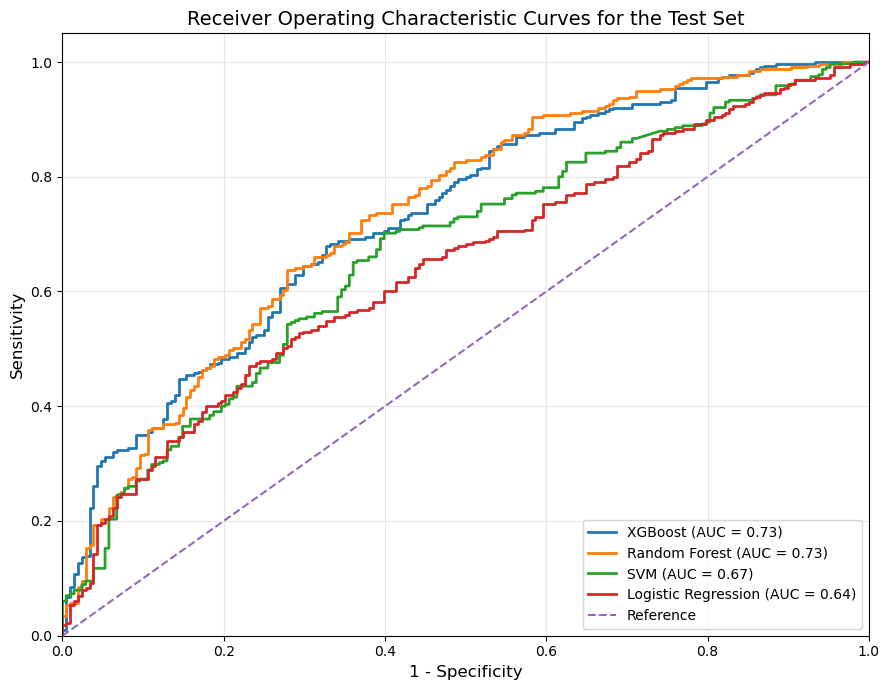

In [68]:
# ============================================================
# ROC-AUC CURVES — FINAL TEST SET — ALL FOUR MODELS
# ============================================================

import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

# ------------------------------------------------------------
# GET TEST-SET PREDICTED PROBABILITIES
# ------------------------------------------------------------

# XGBoost
xgb_test_prob = xgb_model.predict_proba(
    X_test_processed
)[:, 1]

# Random Forest
rf_test_prob = rf_model.predict_proba(
    X_test_processed
)[:, 1]

# SVM
svm_test_prob = svm_final_model.predict_proba(
    X_test_scaled
)[:, 1]

# Logistic Regression
logreg_test_prob = best_logreg.predict_proba(
    X_test_scaled
)[:, 1]


# ------------------------------------------------------------
# CALCULATE ROC CURVES
# ------------------------------------------------------------

xgb_fpr, xgb_tpr, _ = roc_curve(y_test, xgb_test_prob)
rf_fpr, rf_tpr, _ = roc_curve(y_test, rf_test_prob)
svm_fpr, svm_tpr, _ = roc_curve(y_test, svm_test_prob)
logreg_fpr, logreg_tpr, _ = roc_curve(y_test, logreg_test_prob)


# ------------------------------------------------------------
# CALCULATE ROC-AUC
# ------------------------------------------------------------

xgb_auc = roc_auc_score(y_test, xgb_test_prob)
rf_auc = roc_auc_score(y_test, rf_test_prob)
svm_auc = roc_auc_score(y_test, svm_test_prob)
logreg_auc = roc_auc_score(y_test, logreg_test_prob)


# ============================================================
# PLOT ALL FOUR ROC CURVES
# ============================================================

plt.figure(figsize=(9, 7))

plt.plot(
    xgb_fpr,
    xgb_tpr,
    linewidth=2,
    label=f'XGBoost (AUC = {xgb_auc:.2f})'
)

plt.plot(
    rf_fpr,
    rf_tpr,
    linewidth=2,
    label=f'Random Forest (AUC = {rf_auc:.2f})'
)

plt.plot(
    svm_fpr,
    svm_tpr,
    linewidth=2,
    label=f'SVM (AUC = {svm_auc:.2f})'
)

plt.plot(
    logreg_fpr,
    logreg_tpr,
    linewidth=2,
    label=f'Logistic Regression (AUC = {logreg_auc:.2f})'
)

# Reference line
plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    linewidth=1.5,
    label='Reference'
)

# ------------------------------------------------------------
# AXES AND TITLE
# ------------------------------------------------------------

plt.xlabel('1 - Specificity', fontsize=12)
plt.ylabel('Sensitivity', fontsize=12)

plt.title(
    'Receiver Operating Characteristic Curves for the Test Set',
    fontsize=14
)

plt.xlim(0, 1)
plt.ylim(0, 1.05)

plt.legend(
    loc='lower right',
    fontsize=10
)

plt.grid(alpha=0.3)

plt.tight_layout()

plt.show()

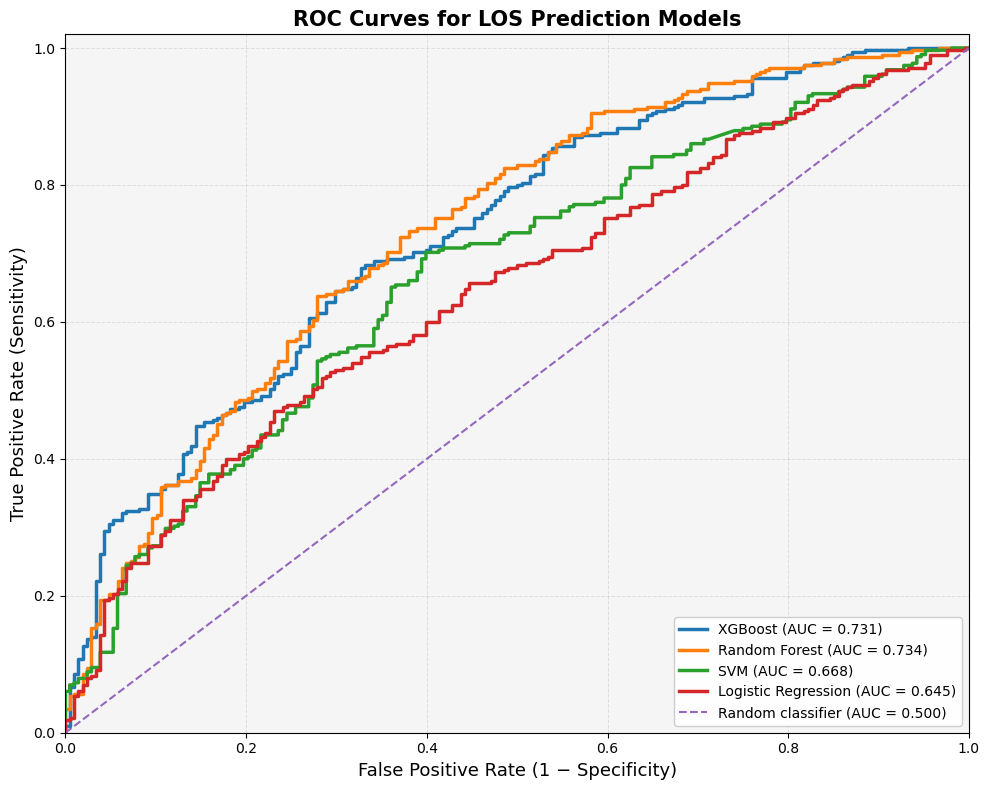

In [70]:
# ============================================================
# ROC CURVES — FINAL TEST SET — ALL FOUR LOS MODELS
# ============================================================

import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

# ------------------------------------------------------------
# GET TEST-SET PREDICTED PROBABILITIES
# ------------------------------------------------------------

# XGBoost
xgb_test_prob = xgb_model.predict_proba(
    X_test_processed
)[:, 1]

# Random Forest
rf_test_prob = rf_model.predict_proba(
    X_test_processed
)[:, 1]

# SVM
svm_test_prob = svm_final_model.predict_proba(
    X_test_scaled
)[:, 1]

# Logistic Regression
logreg_test_prob = best_logreg.predict_proba(
    X_test_scaled
)[:, 1]


# ============================================================
# CALCULATE ROC CURVES AND AUC
# ============================================================

# XGBoost
xgb_fpr, xgb_tpr, _ = roc_curve(
    y_test,
    xgb_test_prob
)
xgb_auc = roc_auc_score(
    y_test,
    xgb_test_prob
)

# Random Forest
rf_fpr, rf_tpr, _ = roc_curve(
    y_test,
    rf_test_prob
)
rf_auc = roc_auc_score(
    y_test,
    rf_test_prob
)

# SVM
svm_fpr, svm_tpr, _ = roc_curve(
    y_test,
    svm_test_prob
)
svm_auc = roc_auc_score(
    y_test,
    svm_test_prob
)

# Logistic Regression
logreg_fpr, logreg_tpr, _ = roc_curve(
    y_test,
    logreg_test_prob
)
logreg_auc = roc_auc_score(
    y_test,
    logreg_test_prob
)


# ============================================================
# CREATE FIGURE
# ============================================================

fig, ax = plt.subplots(figsize=(10, 8))

# Shaded background
ax.set_facecolor("#f5f5f5")


# ============================================================
# PLOT ROC CURVES
# ============================================================

ax.plot(
    xgb_fpr,
    xgb_tpr,
    linewidth=2.5,
    label=f"XGBoost (AUC = {xgb_auc:.3f})"
)

ax.plot(
    rf_fpr,
    rf_tpr,
    linewidth=2.5,
    label=f"Random Forest (AUC = {rf_auc:.3f})"
)

ax.plot(
    svm_fpr,
    svm_tpr,
    linewidth=2.5,
    label=f"SVM (AUC = {svm_auc:.3f})"
)

ax.plot(
    logreg_fpr,
    logreg_tpr,
    linewidth=2.5,
    label=f"Logistic Regression (AUC = {logreg_auc:.3f})"
)


# ============================================================
# RANDOM CLASSIFIER
# ============================================================

ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1.5,
    label="Random classifier (AUC = 0.500)"
)


# ============================================================
# AXES
# ============================================================

ax.set_xlabel(
    "False Positive Rate (1 − Specificity)",
    fontsize=13
)

ax.set_ylabel(
    "True Positive Rate (Sensitivity)",
    fontsize=13
)

ax.set_title(
    "ROC Curves for LOS Prediction Models",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)


# ============================================================
# GRID
# ============================================================

ax.grid(
    True,
    linestyle="--",
    linewidth=0.7,
    alpha=0.35
)


# ============================================================
# LEGEND
# ============================================================

ax.legend(
    loc="lower right",
    fontsize=10,
    frameon=True,
    framealpha=0.95
)


# ============================================================
# FINAL LAYOUT
# ============================================================

plt.tight_layout()
plt.show()

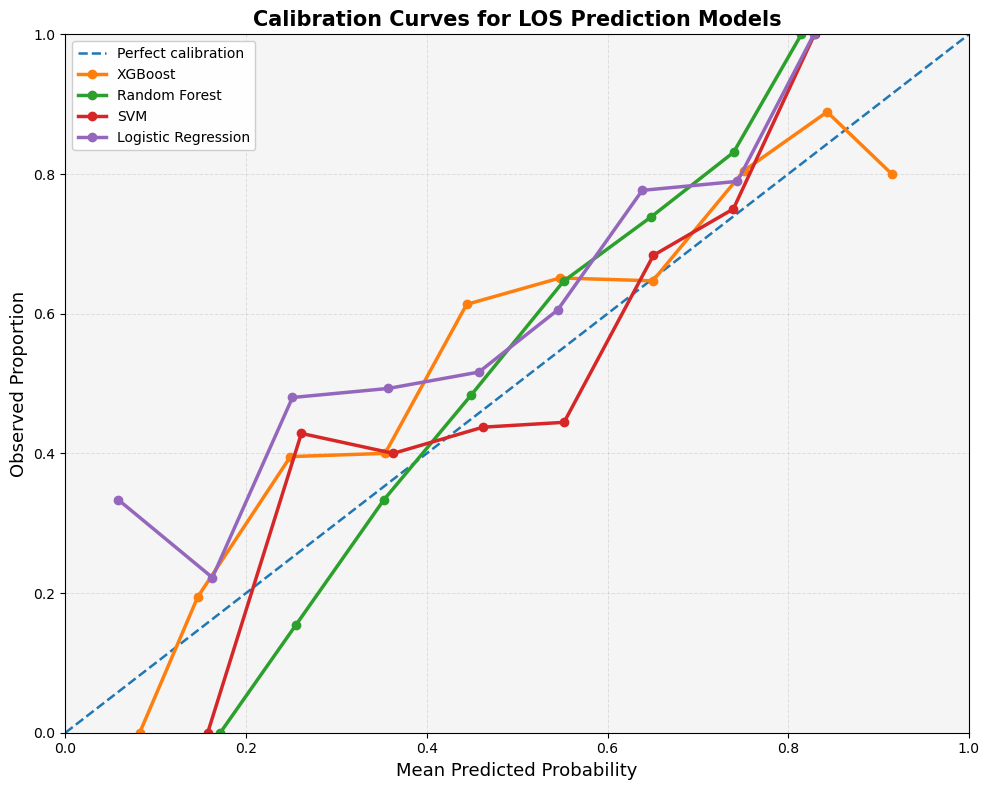

In [71]:
# ============================================================
# CALIBRATION PLOT — FINAL TEST SET — ALL FOUR LOS MODELS
# ============================================================

import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve

# ------------------------------------------------------------
# GET TEST-SET PREDICTED PROBABILITIES
# ------------------------------------------------------------

# XGBoost
xgb_test_prob = xgb_model.predict_proba(
    X_test_processed
)[:, 1]

# Random Forest
rf_test_prob = rf_model.predict_proba(
    X_test_processed
)[:, 1]

# SVM
svm_test_prob = svm_final_model.predict_proba(
    X_test_scaled
)[:, 1]

# Logistic Regression
logreg_test_prob = best_logreg.predict_proba(
    X_test_scaled
)[:, 1]


# ============================================================
# CALCULATE CALIBRATION CURVES
# ============================================================

xgb_fraction_pos, xgb_mean_pred = calibration_curve(
    y_test,
    xgb_test_prob,
    n_bins=10,
    strategy='uniform'
)

rf_fraction_pos, rf_mean_pred = calibration_curve(
    y_test,
    rf_test_prob,
    n_bins=10,
    strategy='uniform'
)

svm_fraction_pos, svm_mean_pred = calibration_curve(
    y_test,
    svm_test_prob,
    n_bins=10,
    strategy='uniform'
)

logreg_fraction_pos, logreg_mean_pred = calibration_curve(
    y_test,
    logreg_test_prob,
    n_bins=10,
    strategy='uniform'
)


# ============================================================
# CREATE FIGURE
# ============================================================

fig, ax = plt.subplots(figsize=(10, 8))

# Shaded background
ax.set_facecolor("#f5f5f5")


# ============================================================
# PERFECT CALIBRATION REFERENCE
# ============================================================

ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1.8,
    label="Perfect calibration"
)


# ============================================================
# XGBOOST
# ============================================================

ax.plot(
    xgb_mean_pred,
    xgb_fraction_pos,
    marker="o",
    markersize=6,
    linewidth=2.5,
    label="XGBoost"
)


# ============================================================
# RANDOM FOREST
# ============================================================

ax.plot(
    rf_mean_pred,
    rf_fraction_pos,
    marker="o",
    markersize=6,
    linewidth=2.5,
    label="Random Forest"
)


# ============================================================
# SVM
# ============================================================

ax.plot(
    svm_mean_pred,
    svm_fraction_pos,
    marker="o",
    markersize=6,
    linewidth=2.5,
    label="SVM"
)


# ============================================================
# LOGISTIC REGRESSION
# ============================================================

ax.plot(
    logreg_mean_pred,
    logreg_fraction_pos,
    marker="o",
    markersize=6,
    linewidth=2.5,
    label="Logistic Regression"
)


# ============================================================
# AXES
# ============================================================

ax.set_xlabel(
    "Mean Predicted Probability",
    fontsize=13
)

ax.set_ylabel(
    "Observed Proportion",
    fontsize=13
)

ax.set_title(
    "Calibration Curves for LOS Prediction Models",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlim(0, 1)
ax.set_ylim(0, 1)


# ============================================================
# GRID
# ============================================================

ax.grid(
    True,
    linestyle="--",
    linewidth=0.7,
    alpha=0.35
)


# ============================================================
# LEGEND
# ============================================================

ax.legend(
    loc="upper left",
    fontsize=10,
    frameon=True,
    framealpha=0.95
)


# ============================================================
# FINAL LAYOUT
# ============================================================

plt.tight_layout()
plt.show()

In [50]:
# ============================================================
# FOUR LOS MODELS — FINAL TEST PERFORMANCE TABLE
# ============================================================

import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

# ============================================================
# 1. FUNCTION TO CALCULATE MODEL METRICS
# ============================================================

def calculate_model_metrics(
    y_train,
    train_prob,
    y_test,
    test_pred,
    test_prob
):

    # ----------------------------
    # Training AUROC
    # ----------------------------

    train_auc = roc_auc_score(
        y_train,
        train_prob
    )

    # ----------------------------
    # Test-set metrics
    # ----------------------------

    accuracy = accuracy_score(
        y_test,
        test_pred
    )

    precision = precision_score(
        y_test,
        test_pred,
        zero_division=0
    )

    sensitivity = recall_score(
        y_test,
        test_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        test_pred,
        zero_division=0
    )

    test_auc = roc_auc_score(
        y_test,
        test_prob
    )

    # ----------------------------
    # Specificity
    # ----------------------------

    tn, fp, fn, tp = confusion_matrix(
        y_test,
        test_pred,
        labels=[0, 1]
    ).ravel()

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else 0
    )

    # ----------------------------
    # Training–test AUROC gap
    # ----------------------------

    auc_gap = train_auc - test_auc

    return [
        accuracy,
        precision,
        sensitivity,
        specificity,
        f1,
        train_auc,
        test_auc,
        auc_gap
    ]


# ============================================================
# 2. GET TRAINING PREDICTED PROBABILITIES
# ============================================================

# ----------------------------
# XGBoost
# ----------------------------

xgb_train_prob = xgb_model.predict_proba(
    X_train_processed
)[:, 1]


# ----------------------------
# Random Forest
# ----------------------------

rf_train_prob = rf_model.predict_proba(
    X_train_processed
)[:, 1]


# ----------------------------
# SVM
# ----------------------------

svm_train_prob = svm_final_model.predict_proba(
    X_train_scaled
)[:, 1]


# ----------------------------
# Logistic Regression
# ----------------------------

logreg_train_prob = best_logreg.predict_proba(
    X_train_scaled
)[:, 1]


# ============================================================
# 3. GET TEST-SET PREDICTIONS AND PROBABILITIES
# ============================================================

# ----------------------------
# XGBoost
# ----------------------------

xgb_test_pred = xgb_model.predict(
    X_test_processed
)

xgb_test_prob = xgb_model.predict_proba(
    X_test_processed
)[:, 1]


# ----------------------------
# Random Forest
# ----------------------------

rf_test_pred = rf_model.predict(
    X_test_processed
)

rf_test_prob = rf_model.predict_proba(
    X_test_processed
)[:, 1]


# ----------------------------
# SVM
# ----------------------------

y_test_pred = svm_final_model.predict(
    X_test_scaled
)

svm_test_prob = svm_final_model.predict_proba(
    X_test_scaled
)[:, 1]


# ----------------------------
# Logistic Regression
# ----------------------------

logreg_test_y_pred = best_logreg.predict(
    X_test_scaled
)

logreg_test_y_prob = best_logreg.predict_proba(
    X_test_scaled
)[:, 1]


# ============================================================
# 4. BUILD FOUR-MODEL PERFORMANCE TABLE
# ============================================================

results = []


# ----------------------------
# XGBoost
# ----------------------------

results.append([
    "XGBoost",
    *calculate_model_metrics(
        y_train,
        xgb_train_prob,
        y_test,
        xgb_test_pred,
        xgb_test_prob
    )
])


# ----------------------------
# Random Forest
# ----------------------------

results.append([
    "Random Forest",
    *calculate_model_metrics(
        y_train,
        rf_train_prob,
        y_test,
        rf_test_pred,
        rf_test_prob
    )
])


# ----------------------------
# SVM
# ----------------------------

results.append([
    "SVM",
    *calculate_model_metrics(
        y_train,
        svm_train_prob,
        y_test,
        y_test_pred,
        svm_test_prob
    )
])


# ----------------------------
# Logistic Regression
# ----------------------------

results.append([
    "Logistic Regression",
    *calculate_model_metrics(
        y_train,
        logreg_train_prob,
        y_test,
        logreg_test_y_pred,
        logreg_test_y_prob
    )
])


# ============================================================
# 5. CREATE PERFORMANCE DATAFRAME
# ============================================================

performance_table = pd.DataFrame(
    results,
    columns=[
        "Model",
        "Accuracy",
        "Precision",
        "Sensitivity",
        "Specificity",
        "F1-score",
        "Training AUC",
        "Test AUC",
        "AUC Gap"
    ]
)


# ============================================================
# 6. ROUND NUMERIC VALUES
# ============================================================

numeric_columns = performance_table.select_dtypes(
    include="number"
).columns

performance_table[numeric_columns] = (
    performance_table[numeric_columns].round(4)
)


# ============================================================
# 7. DISPLAY FINAL TEST PERFORMANCE
# ============================================================

print("\n" + "=" * 110)
print("FOUR-MODEL LOS PREDICTION — FINAL TEST PERFORMANCE")
print("=" * 110)

print(
    performance_table.to_string(
        index=False
    )
)


FOUR-MODEL LOS PREDICTION — FINAL TEST PERFORMANCE
              Model  Accuracy  Precision  Sensitivity  Specificity  F1-score  Training AUC  Test AUC  AUC Gap
            XGBoost    0.6635     0.7294       0.7016       0.6058    0.7152        0.9157    0.7308   0.1849
      Random Forest    0.6845     0.7246       0.7683       0.5577    0.7458        0.9769    0.7327   0.2442
                SVM    0.6405     0.6966       0.7143       0.5288    0.7053        0.7556    0.6684   0.0872
Logistic Regression    0.6099     0.6894       0.6413       0.5625    0.6645        0.6562    0.6445   0.0117


# validation set performance

In [51]:
# ============================================================
# FOUR LOS MODELS — VALIDATION PERFORMANCE TABLE
# ============================================================

import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

# ============================================================
# 1. FUNCTION TO CALCULATE MODEL METRICS
# ============================================================

def calculate_validation_metrics(
    y_train,
    train_prob,
    y_validation,
    validation_pred,
    validation_prob
):

    # ----------------------------
    # Training AUC
    # ----------------------------

    train_auc = roc_auc_score(
        y_train,
        train_prob
    )

    # ----------------------------
    # Validation metrics
    # ----------------------------

    accuracy = accuracy_score(
        y_validation,
        validation_pred
    )

    precision = precision_score(
        y_validation,
        validation_pred,
        zero_division=0
    )

    sensitivity = recall_score(
        y_validation,
        validation_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_validation,
        validation_pred,
        zero_division=0
    )

    validation_auc = roc_auc_score(
        y_validation,
        validation_prob
    )

    # ----------------------------
    # Specificity
    # ----------------------------

    tn, fp, fn, tp = confusion_matrix(
        y_validation,
        validation_pred,
        labels=[0, 1]
    ).ravel()

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else 0
    )

    # ----------------------------
    # Training-validation AUC gap
    # ----------------------------

    auc_gap = train_auc - validation_auc

    return [
        accuracy,
        precision,
        sensitivity,
        specificity,
        f1,
        train_auc,
        validation_auc,
        auc_gap
    ]


# ============================================================
# 2. GET TRAINING PREDICTED PROBABILITIES
# ============================================================

# XGBoost

xgb_train_prob = xgb_model.predict_proba(
    X_train_processed
)[:, 1]


# Random Forest

rf_train_prob = rf_model.predict_proba(
    X_train_processed
)[:, 1]


# SVM

svm_train_prob = svm_final_model.predict_proba(
    X_train_scaled
)[:, 1]


# Logistic Regression

logreg_train_prob = best_logreg.predict_proba(
    X_train_scaled
)[:, 1]


# ============================================================
# 3. GET VALIDATION PREDICTIONS AND PROBABILITIES
# ============================================================

# ----------------------------
# XGBoost
# ----------------------------

xgb_validation_pred = xgb_model.predict(
    X_validation_processed
)

xgb_validation_prob = xgb_model.predict_proba(
    X_validation_processed
)[:, 1]


# ----------------------------
# Random Forest
# ----------------------------

rf_validation_pred = rf_model.predict(
    X_validation_processed
)

rf_validation_prob = rf_model.predict_proba(
    X_validation_processed
)[:, 1]


# ----------------------------
# SVM
# ----------------------------

svm_validation_pred = svm_final_model.predict(
    X_validation_scaled
)

svm_validation_prob = svm_final_model.predict_proba(
    X_validation_scaled
)[:, 1]


# ----------------------------
# Logistic Regression
# ----------------------------

logreg_validation_pred = best_logreg.predict(
    X_validation_scaled
)

logreg_validation_prob = best_logreg.predict_proba(
    X_validation_scaled
)[:, 1]


# ============================================================
# 4. BUILD FOUR-MODEL VALIDATION PERFORMANCE TABLE
# ============================================================

results = []


# ----------------------------
# XGBoost
# ----------------------------

results.append([
    "XGBoost",
    *calculate_validation_metrics(
        y_train,
        xgb_train_prob,
        y_validation,
        xgb_validation_pred,
        xgb_validation_prob
    )
])


# ----------------------------
# Random Forest
# ----------------------------

results.append([
    "Random Forest",
    *calculate_validation_metrics(
        y_train,
        rf_train_prob,
        y_validation,
        rf_validation_pred,
        rf_validation_prob
    )
])


# ----------------------------
# SVM
# ----------------------------

results.append([
    "SVM",
    *calculate_validation_metrics(
        y_train,
        svm_train_prob,
        y_validation,
        svm_validation_pred,
        svm_validation_prob
    )
])


# ----------------------------
# Logistic Regression
# ----------------------------

results.append([
    "Logistic Regression",
    *calculate_validation_metrics(
        y_train,
        logreg_train_prob,
        y_validation,
        logreg_validation_pred,
        logreg_validation_prob
    )
])


# ============================================================
# 5. CREATE VALIDATION PERFORMANCE DATAFRAME
# ============================================================

validation_performance_table = pd.DataFrame(
    results,
    columns=[
        "Model",
        "Accuracy",
        "Precision",
        "Sensitivity",
        "Specificity",
        "F1-score",
        "Training AUC",
        "Validation AUC",
        "AUC Gap"
    ]
)


# ============================================================
# 6. ROUND NUMERIC VALUES
# ============================================================

numeric_columns = validation_performance_table.select_dtypes(
    include="number"
).columns

validation_performance_table[numeric_columns] = (
    validation_performance_table[numeric_columns].round(4)
)


# ============================================================
# 7. DISPLAY VALIDATION PERFORMANCE
# ============================================================

print("\n" + "=" * 115)
print("FOUR-MODEL LOS PREDICTION — VALIDATION PERFORMANCE")
print("=" * 115)

print(
    validation_performance_table.to_string(
        index=False
    )
)


FOUR-MODEL LOS PREDICTION — VALIDATION PERFORMANCE
              Model  Accuracy  Precision  Sensitivity  Specificity  F1-score  Training AUC  Validation AUC  AUC Gap
            XGBoost    0.6743     0.7273       0.7365       0.5797    0.7319        0.9157          0.7038   0.2119
      Random Forest    0.6954     0.7281       0.7905       0.5507    0.7580        0.9769          0.7149   0.2620
                SVM    0.6571     0.7024       0.7492       0.5169    0.7250        0.7556          0.6738   0.0818
Logistic Regression    0.6379     0.7086       0.6794       0.5749    0.6937        0.6562          0.6571  -0.0008
